## FIN41360 Assignment 2 - Risk Modelling Analysis

# Set up 

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

path = "COS PARM.xlsx"
investment = 1_000_000

# Load Equity Data 

In [2]:
lr_raw = pd.read_excel(path, sheet_name="Log Returns", header=0)

log_return_cols = list(range(2, 90, 3))
date_col = lr_raw.iloc[:, 0]

stock_returns = lr_raw.iloc[:, log_return_cols].copy()
stock_returns.index = pd.to_datetime(date_col)



stock_returns.columns = [
    'AAPL','GS','CAT','MSFT','AMGN','HD','SHW','AXP',
    'MCD','JPM','UNH','V','TRV','JNJ','IBM','HON',
    'AMZN','BA','CVX','NVDA','CRM','MMM','PG','WMT',
    'MRK','DIS','CSCO','KO','VZ','NKE'
]

# Drop fully blank rows but do NOT drop row 0 with iloc[1:]
# Row 0 has NaN returns but a valid date — we keep the date range intact
stock_returns = stock_returns.dropna(how='all')
stock_returns = stock_returns.apply(pd.to_numeric, errors='coerce')

# Only drop rows where ALL 30 stocks have NaN — preserves partial rows
stock_returns = stock_returns.dropna(how='all')

# Remove only the return NaNs, keeping the index intact
stock_returns = stock_returns.dropna(thresh=25)  # need at least 25 of 30 stocks

print(f"Stocks loaded: {stock_returns.shape[0]} days, {stock_returns.shape[1]} stocks")
print(f"From {stock_returns.index[0].date()} to {stock_returns.index[-1].date()}")
print("First 3 dates:", stock_returns.index[:3].tolist())
print("Last 3 dates:", stock_returns.index[-3:].tolist())
print(f"Stocks loaded: {stock_returns.shape[0]} days, {stock_returns.shape[1]} stocks")
print(f"Prices from 28 Mar 2022, returns from {stock_returns.index[0].date()} to {stock_returns.index[-1].date()}")
print("Note: first return is 29 Mar 2022 as log returns require two consecutive prices")

Stocks loaded: 1003 days, 30 stocks
From 2022-03-29 to 2026-03-27
First 3 dates: [Timestamp('2022-03-29 00:00:00'), Timestamp('2022-03-30 00:00:00'), Timestamp('2022-03-31 00:00:00')]
Last 3 dates: [Timestamp('2026-03-25 00:00:00'), Timestamp('2026-03-26 00:00:00'), Timestamp('2026-03-27 00:00:00')]
Stocks loaded: 1003 days, 30 stocks
Prices from 28 Mar 2022, returns from 2022-03-29 to 2026-03-27
Note: first return is 29 Mar 2022 as log returns require two consecutive prices


## Stock Return heatmap & Correlation Structure

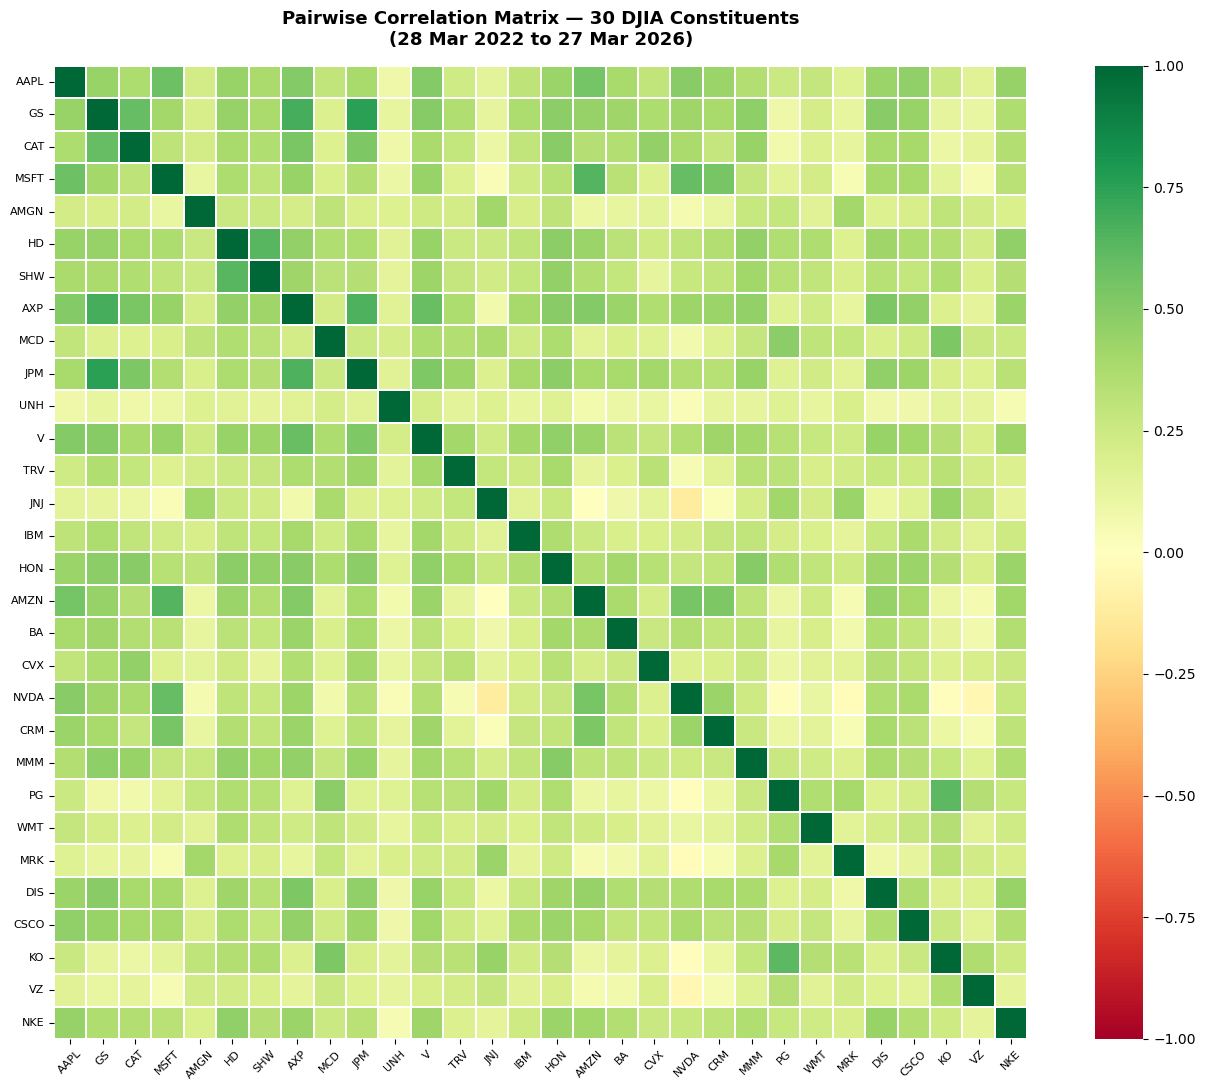

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = stock_returns.corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr_matrix, 
            annot=False,
            cmap='RdYlGn',
            vmin=-1, vmax=1,
            center=0,
            square=True,
            linewidths=0.3,
            ax=ax)

ax.set_title('Pairwise Correlation Matrix — 30 DJIA Constituents\n(28 Mar 2022 to 27 Mar 2026)', 
             fontsize=13, fontweight='bold', pad=15)
ax.tick_params(axis='x', rotation=45, labelsize=8)
ax.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Load Bond Data and Compute Log Returns

In [4]:
bi_raw = pd.read_excel(path, sheet_name="Bond Index Data", header=None)

# Col 0 = dates, col 1 = prices
bond_dates  = pd.to_datetime(bi_raw.iloc[:, 0], errors='coerce')
bond_prices = pd.to_numeric(bi_raw.iloc[:, 1], errors='coerce')

bond_df = pd.DataFrame({'price': bond_prices.values}, index=bond_dates).dropna()

# Compute log returns directly in Python
bond_returns = np.log(bond_df['price'] / bond_df['price'].shift(1)).dropna()

print(f"Bond loaded: {len(bond_returns)} days")
print(f"From {bond_returns.index[0].date()} to {bond_returns.index[-1].date()}")

Bond loaded: 1024 days
From 2022-03-29 to 2026-03-27


# Set Parameters, Ensure dates align and build the three portfolios with a 60/40 weighting


In [5]:
# Keep only dates that appear in both equity and bond data
common_dates = stock_returns.index.intersection(bond_returns.index)

equity_aligned = stock_returns.loc[common_dates]
bond_aligned   = bond_returns.loc[common_dates]

# Portfolio 1: equal-weighted across all 30 DJIA stocks
equity_portfolio = equity_aligned.mean(axis=1)

# Portfolio 2: Bloomberg US Agg Bond Index
bond_portfolio = bond_aligned.copy()

# Portfolio 3: 60/40 split, motivated by Markowitz diversification
# Equity and bonds have historically shown negative correlation,
# so a blended portfolio reduces overall variance
combined_portfolio = 0.6 * equity_portfolio + 0.4 * bond_portfolio

portfolios = {
    'Equity':   equity_portfolio,
    'Bond':     bond_portfolio,
    'Combined': combined_portfolio
}

print(f"Aligned dataset: {len(common_dates)} common trading days")
for name, p in portfolios.items():
    print(f"  {name}: mean={p.mean():.5f}, std={p.std():.5f}, obs={len(p)}")

Aligned dataset: 1000 common trading days
  Equity: mean=0.00027, std=0.00956, obs=1000
  Bond: mean=0.00007, std=0.00390, obs=1000
  Combined: mean=0.00019, std=0.00625, obs=1000


## Portfolio Return Time Series

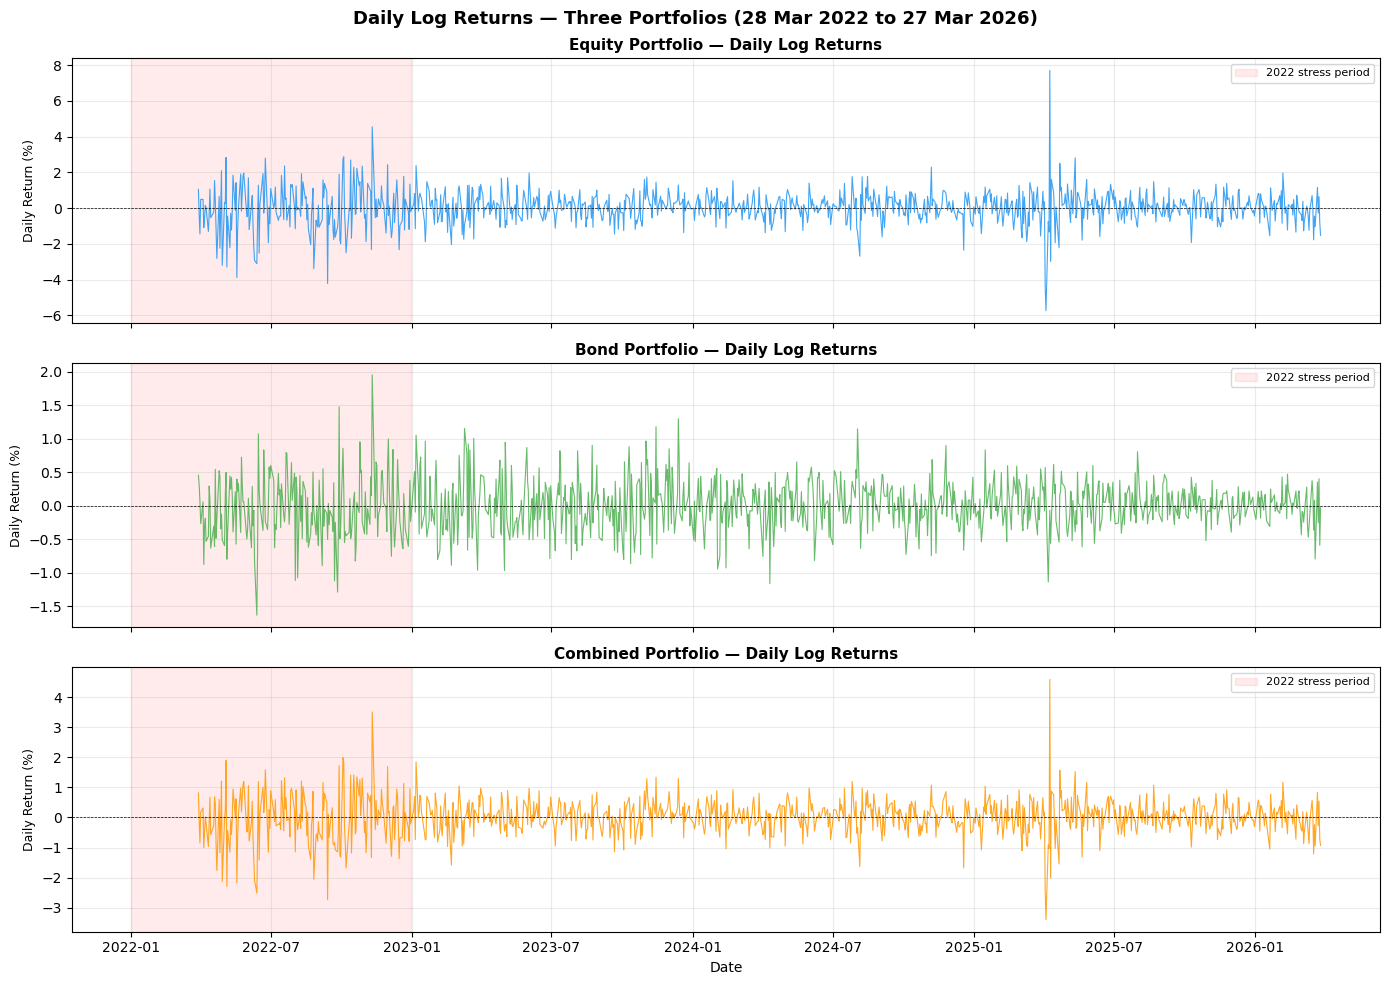

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

colors = {'Equity': '#2196F3', 'Bond': '#4CAF50', 'Combined': '#FF9800'}

for ax, (name, ret) in zip(axes, portfolios.items()):
    ax.plot(ret.index, ret * 100, color=colors[name], 
            linewidth=0.8, alpha=0.85)
    ax.axhline(0, color='black', linewidth=0.5, linestyle='--')
    ax.set_ylabel('Daily Return (%)', fontsize=9)
    ax.set_title(f'{name} Portfolio — Daily Log Returns', 
                 fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.25)

    # Shade the 2022 stress period
    ax.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'),
               alpha=0.08, color='red', label='2022 stress period')
    ax.legend(fontsize=8)

axes[-1].set_xlabel('Date', fontsize=10)
plt.suptitle('Daily Log Returns — Three Portfolios (28 Mar 2022 to 27 Mar 2026)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('portfolio_returns.png', dpi=150, bbox_inches='tight')
plt.show()

## Cumulative Performance

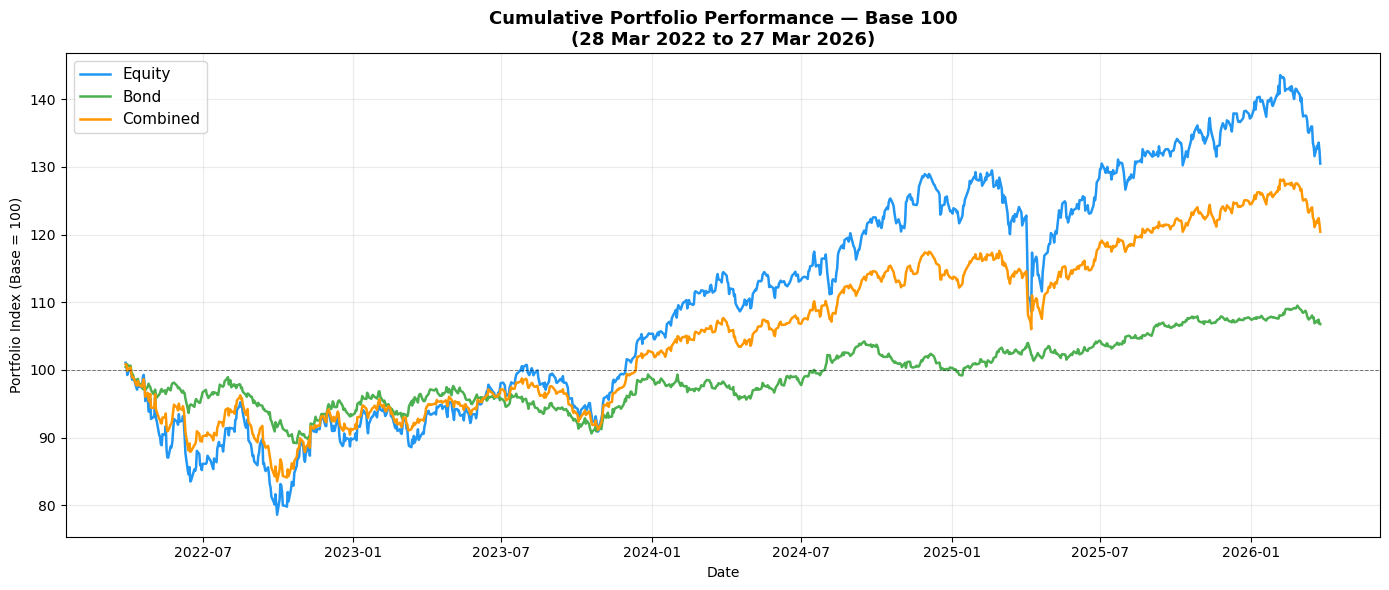

In [7]:
fig, ax = plt.subplots(figsize=(14, 6))

for name, ret in portfolios.items():
    cum = 100 * np.exp(np.cumsum(ret))
    ax.plot(ret.index, cum, color=colors[name], 
            label=name, linewidth=1.8)

ax.axhline(100, color='black', linewidth=0.7, linestyle='--', alpha=0.5)
ax.set_title('Cumulative Portfolio Performance — Base 100\n(28 Mar 2022 to 27 Mar 2026)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Date', fontsize=10)
ax.set_ylabel('Portfolio Index (Base = 100)', fontsize=10)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig('cumulative_returns.png', dpi=150, bbox_inches='tight')
plt.show()

# Parametric VaR (99% confidence)

In [8]:
def parametric_var(returns, confidence=0.99, investment=1_000_000):
    mu    = returns.mean()
    sigma = returns.std()
    # Left-tail quantile: VaR = -(mu + z_alpha * sigma)
    # where z_alpha = norm.ppf(1-confidence) is negative
    # Equivalently: -mu + z * sigma where z = norm.ppf(confidence) > 0
    z   = stats.norm.ppf(confidence)
    var = (-mu + z * sigma) * investment
    return var  # already positive since z*sigma dominates

def historical_var(returns, confidence=0.99, investment=1_000_000):
    r   = np.array(returns, dtype=float)
    r   = r[~np.isnan(r)]
    var = -np.percentile(r, (1 - confidence) * 100)
    return var * investment

print("Parametric VaR (99%, $1M):")
for name, ret in portfolios.items():
    print(f"  {name}: ${parametric_var(ret):,.2f}")

Parametric VaR (99%, $1M):
  Equity: $21,964.00
  Bond: $9,017.84
  Combined: $14,345.64


## Return Distribution with Normal Overlay

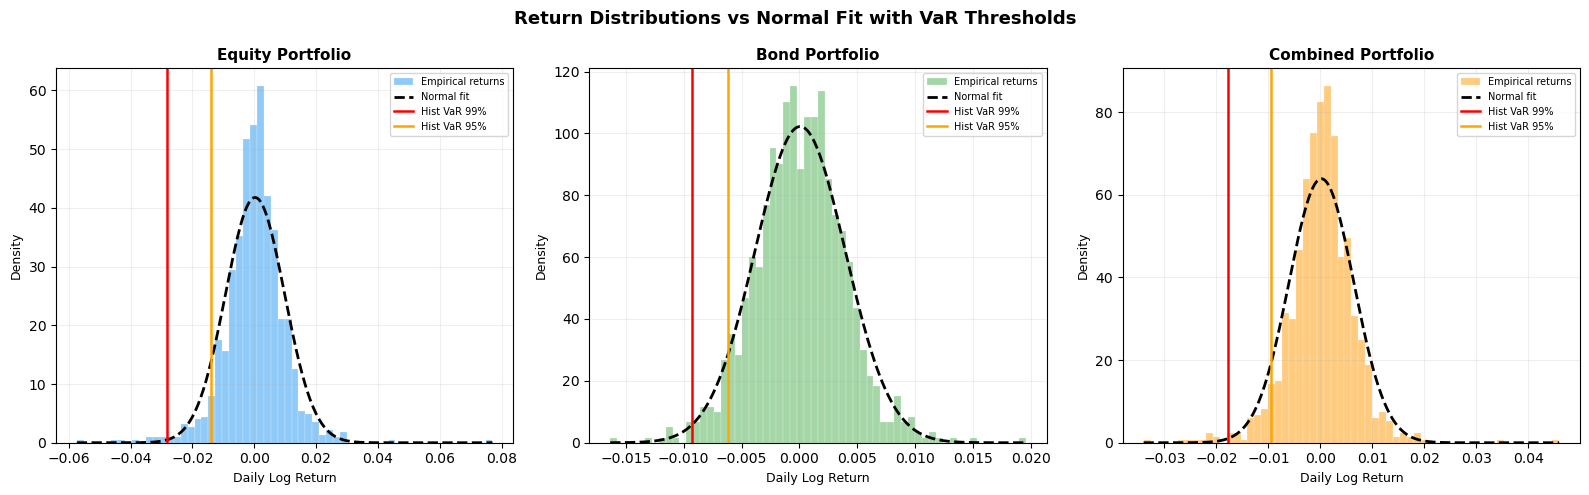

In [9]:
from scipy import stats as scipy_stats

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, ret) in zip(axes, portfolios.items()):
    r = np.array(ret, dtype=float)
    
    ax.hist(r, bins=60, density=True, color=colors[name],
            alpha=0.5, label='Empirical returns', edgecolor='white', linewidth=0.3)
    
    # Fitted normal curve
    x_range = np.linspace(r.min(), r.max(), 300)
    normal_pdf = scipy_stats.norm.pdf(x_range, r.mean(), r.std())
    ax.plot(x_range, normal_pdf, color='black', linewidth=2,
            linestyle='--', label='Normal fit')
    
    # Mark VaR lines
    var_99 = -historical_var(ret) / 1_000_000
    var_95 = -historical_var(ret, confidence=0.95) / 1_000_000
    ax.axvline(var_99, color='red', linewidth=1.8, 
               linestyle='-', label='Hist VaR 99%')
    ax.axvline(var_95, color='orange', linewidth=1.8,
               linestyle='-', label='Hist VaR 95%')

    ax.set_title(f'{name} Portfolio', fontsize=11, fontweight='bold')
    ax.set_xlabel('Daily Log Return', fontsize=9)
    ax.set_ylabel('Density', fontsize=9)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.2)

plt.suptitle('Return Distributions vs Normal Fit with VaR Thresholds',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('return_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## QQ Plot to test the normality assumption


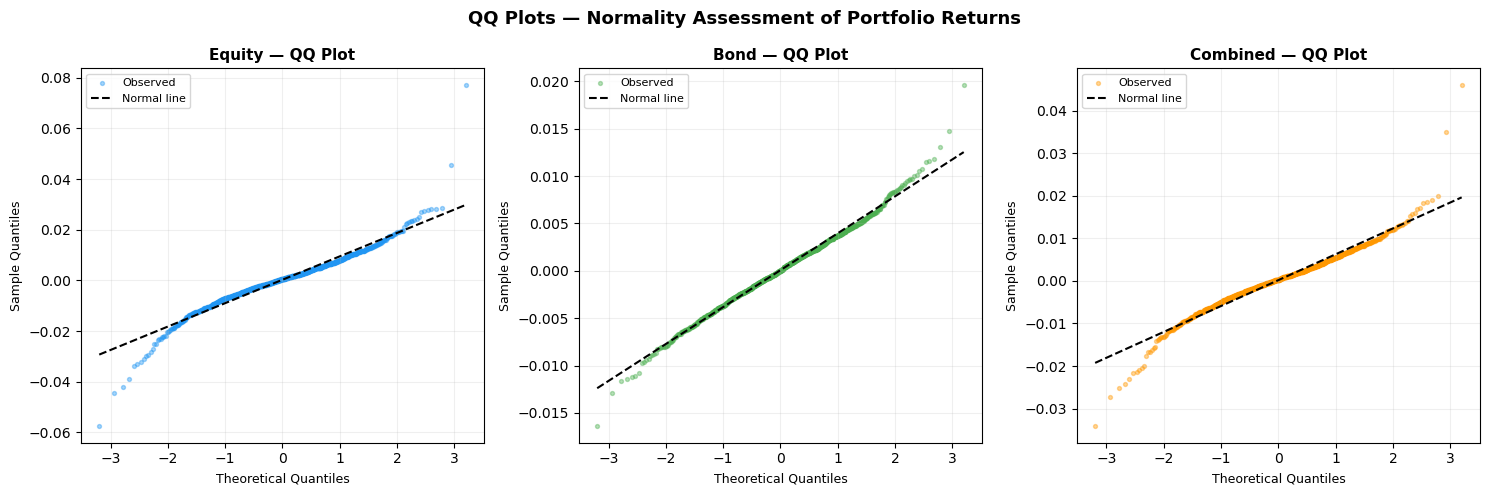

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, ret) in zip(axes, portfolios.items()):
    r = np.array(ret, dtype=float)
    (osm, osr), (slope, intercept, r_sq) = scipy_stats.probplot(r, dist='norm')
    
    ax.scatter(osm, osr, color=colors[name], alpha=0.4, s=8, label='Observed')
    ax.plot(osm, slope * np.array(osm) + intercept, 
            color='black', linewidth=1.5, linestyle='--', label='Normal line')
    
    ax.set_title(f'{name} — QQ Plot', fontsize=11, fontweight='bold')
    ax.set_xlabel('Theoretical Quantiles', fontsize=9)
    ax.set_ylabel('Sample Quantiles', fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

plt.suptitle('QQ Plots — Normality Assessment of Portfolio Returns',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('qq_plots.png', dpi=150, bbox_inches='tight')
plt.show()

# Parametric Expected Shortfall (99%)

In [11]:
def parametric_es(returns, confidence=0.99, investment=1_000_000):
    mu    = returns.mean()
    sigma = returns.std()
    alpha = 1 - confidence
    z     = stats.norm.ppf(confidence)
    # Correct left-tail ES: -mu + sigma * phi(z) / alpha
    es = (-mu + sigma * stats.norm.pdf(z) / alpha) * investment
    return es  

print("Parametric ES (99%, $1M):")
for name, ret in portfolios.items():
    print(f"  {name}: ${parametric_es(ret):,.2f}")

Parametric ES (99%, $1M):
  Equity: $25,202.13
  Bond: $10,340.95
  Combined: $16,462.35


## Cornish-Fisher VaR & ES

In [12]:
def cornish_fisher_var(returns, confidence=0.99, investment=1_000_000):
    mu    = returns.mean()
    sigma = returns.std()
    s     = stats.skew(returns)
    k     = stats.kurtosis(returns)
    z     = stats.norm.ppf(confidence)

    z_cf = (z
            + (z**2 - 1) * s / 6
            + (z**3 - 3*z) * k / 24
            - (2*z**3 - 5*z) * s**2 / 36)

    # Left-tail: VaR = -mu + z_cf * sigma
    var = (-mu + z_cf * sigma) * investment
    return var

def cornish_fisher_es(returns, confidence=0.99, investment=1_000_000):
    # ES under Cornish-Fisher: integrate the CF-adjusted quantile over the tail
    mu    = returns.mean()
    sigma = returns.std()
    s     = stats.skew(returns)
    k     = stats.kurtosis(returns)
    alpha = 1 - confidence

    # Numerical integration across the tail using 500 points
    p_tail    = np.linspace(0, alpha, 500)
    z_vals    = stats.norm.ppf(np.clip(p_tail, 1e-6, 1 - 1e-6))
    z_cf_vals = (z_vals
                 + (z_vals**2 - 1) * s / 6
                 + (z_vals**3 - 3*z_vals) * k / 24
                 - (2*z_vals**3 - 5*z_vals) * s**2 / 36)

    quantiles = mu + z_cf_vals * sigma
    es        = -np.trapezoid(quantiles, p_tail) / alpha
    return abs(es) * investment

print("Cornish-Fisher VaR (99%, $1M):")
for name, ret in portfolios.items():
    s = stats.skew(ret)
    k = stats.kurtosis(ret)
    print(f"  {name}: ${cornish_fisher_var(ret):,.2f}  "
          f"(skew={s:.3f}, kurt={k:.3f})")

print("\nCornish-Fisher ES (99%, $1M):")
for name, ret in portfolios.items():
    print(f"  {name}: ${cornish_fisher_es(ret):,.2f}")

print("\nCornish-Fisher VaR (95%, $1M):")
for name, ret in portfolios.items():
    print(f"  {name}: ${cornish_fisher_var(ret, confidence=0.95):,.2f}")

print("\nCornish-Fisher ES (95%, $1M):")
for name, ret in portfolios.items():
    print(f"  {name}: ${cornish_fisher_es(ret, confidence=0.95):,.2f}")

Cornish-Fisher VaR (99%, $1M):
  Equity: $37,977.62  (skew=0.006, kurt=7.149)
  Bond: $10,328.04  (skew=0.099, kurt=1.141)
  Combined: $22,706.72  (skew=0.019, kurt=5.666)

Cornish-Fisher ES (99%, $1M):
  Equity: $58,651.89
  Bond: $12,100.32
  Combined: $33,702.07

Cornish-Fisher VaR (95%, $1M):
  Equity: $14,090.19
  Bond: $6,375.90
  Combined: $9,408.13

Cornish-Fisher ES (95%, $1M):
  Equity: $29,525.18
  Bond: $8,421.83
  Combined: $17,872.44


Note: CF ES at 95% confidence produces anomalously high estimates for the equity and combined portfolios due to high excess kurtosis (7.16). The CF expansion is known to become unreliable at lower confidence levels when kurtosis is extreme. These figures should be interpreted with caution and are flagged as a limitation in the report.

## Monte Carlo VaR and ES

In [13]:
n_sims = 100_000
np.random.seed(42)

# ── Build joint return matrix: equity portfolio + bond ────────────────────────
# Stack the equal-weighted equity portfolio return and bond return side by side
# This captures the equity-bond correlation properly in the simulation

eq_port_returns   = equity_portfolio   # already equal-weighted
bond_port_returns = bond_portfolio

# Combine into a 2-column matrix: [equity_portfolio, bond]
joint_returns = pd.concat([eq_port_returns, bond_port_returns], axis=1)
joint_returns.columns = ['Equity', 'Bond']
joint_returns = joint_returns.dropna()

# Estimate joint mean and covariance
mu_joint  = joint_returns.mean().values
cov_joint = joint_returns.cov().values

print("Equity-Bond Correlation in sample:",
      round(joint_returns.corr().iloc[0, 1], 4))

# Simulate jointly — this preserves the equity-bond correlation
simulated_joint = np.random.multivariate_normal(mu_joint, cov_joint, n_sims)

eq_sim_returns       = simulated_joint[:, 0]
bond_sim_returns     = simulated_joint[:, 1]
combined_sim_returns = 0.6 * eq_sim_returns + 0.4 * bond_sim_returns

eq_sim_pl       = eq_sim_returns   * investment
bond_sim_pl     = bond_sim_returns * investment
combined_sim_pl = combined_sim_returns * investment

mc_simulations = {
    'Equity':   eq_sim_pl,
    'Bond':     bond_sim_pl,
    'Combined': combined_sim_pl
}

print(f"Monte Carlo simulation complete: {n_sims:,} draws, seed=42")
print(f"Simulated equity-bond correlation: "
      f"{np.corrcoef(eq_sim_returns, bond_sim_returns)[0,1]:.4f}")

Equity-Bond Correlation in sample: 0.207
Monte Carlo simulation complete: 100,000 draws, seed=42
Simulated equity-bond correlation: 0.2061


In [14]:
def monte_carlo_var(sim_pl, confidence=0.99):
    return -np.percentile(sim_pl, (1 - confidence) * 100)

def monte_carlo_es(sim_pl, confidence=0.99):
    threshold = np.percentile(sim_pl, (1 - confidence) * 100)
    tail      = sim_pl[sim_pl < threshold]
    return -tail.mean()

print("Monte Carlo VaR (99%, $1M):")
for name, sim in mc_simulations.items():
    print(f"  {name}: ${monte_carlo_var(sim):,.2f}")

print("\nMonte Carlo ES (99%, $1M):")
for name, sim in mc_simulations.items():
    print(f"  {name}: ${monte_carlo_es(sim):,.2f}")

print("\nMonte Carlo VaR (95%, $1M):")
for name, sim in mc_simulations.items():
    print(f"  {name}: ${monte_carlo_var(sim, confidence=0.95):,.2f}")

print("\nMonte Carlo ES (95%, $1M):")
for name, sim in mc_simulations.items():
    print(f"  {name}: ${monte_carlo_es(sim, confidence=0.95):,.2f}")

Monte Carlo VaR (99%, $1M):
  Equity: $22,034.22
  Bond: $8,972.19
  Combined: $14,376.22

Monte Carlo ES (99%, $1M):
  Equity: $25,154.18
  Bond: $10,342.79
  Combined: $16,369.04

Monte Carlo VaR (95%, $1M):
  Equity: $15,597.46
  Bond: $6,368.60
  Combined: $10,173.36

Monte Carlo ES (95%, $1M):
  Equity: $19,549.30
  Bond: $7,980.00
  Combined: $12,746.31


## Monte Carlo P&L Distribution

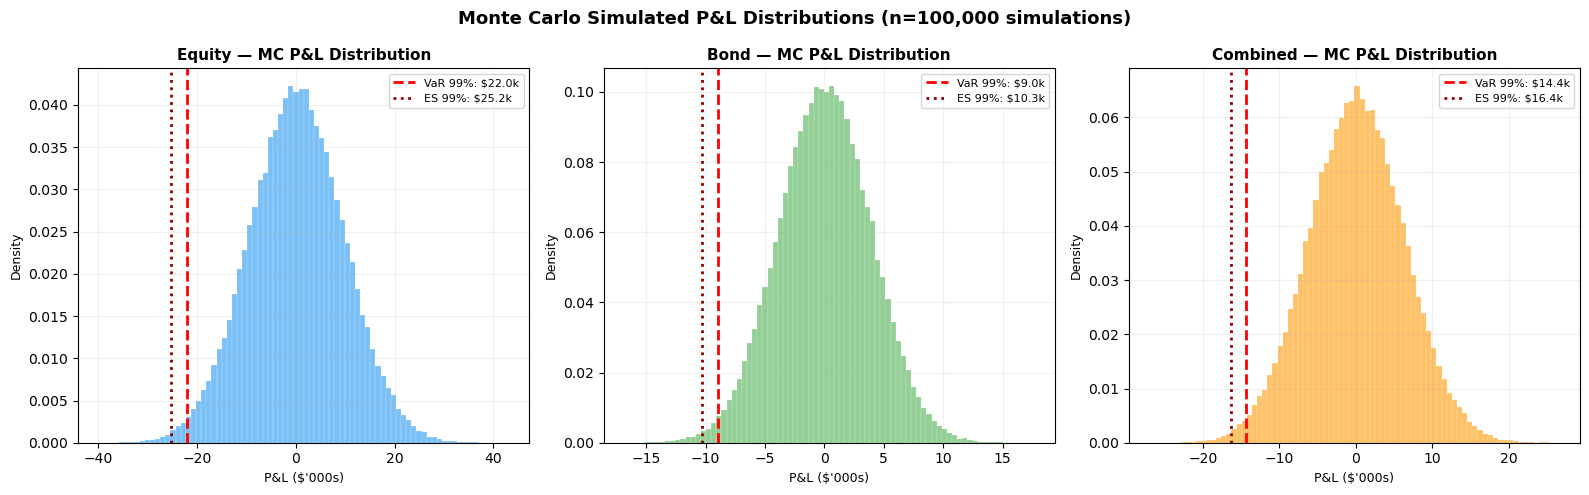

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, sim_pl) in zip(axes, mc_simulations.items()):
    ax.hist(sim_pl / 1000, bins=80, density=True,
            color=colors[name], alpha=0.6, edgecolor='white', linewidth=0.2)

    var_line = monte_carlo_var(sim_pl) / 1000
    es_line  = monte_carlo_es(sim_pl)  / 1000

    ax.axvline(-var_line, color='red', linewidth=2,
               linestyle='--', label=f'VaR 99%: ${var_line:,.1f}k')
    ax.axvline(-es_line,  color='darkred', linewidth=2,
               linestyle=':', label=f'ES 99%: ${es_line:,.1f}k')

    ax.set_title(f'{name} — MC P&L Distribution', 
                 fontsize=11, fontweight='bold')
    ax.set_xlabel("P&L ($'000s)", fontsize=9)
    ax.set_ylabel('Density', fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

plt.suptitle(f'Monte Carlo Simulated P&L Distributions (n={n_sims:,} simulations)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('monte_carlo_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

# Historical Simulation VaR (99%)

In [16]:
# historical_var defined in Cell 16 alongside parametric_var
print("Historical Simulation VaR (99%, $1M):")
for name, ret in portfolios.items():
    print(f"  {name}: ${historical_var(ret):,.2f}")

Historical Simulation VaR (99%, $1M):
  Equity: $28,165.79
  Bond: $9,286.91
  Combined: $17,691.04


## VaR Comparison Chart

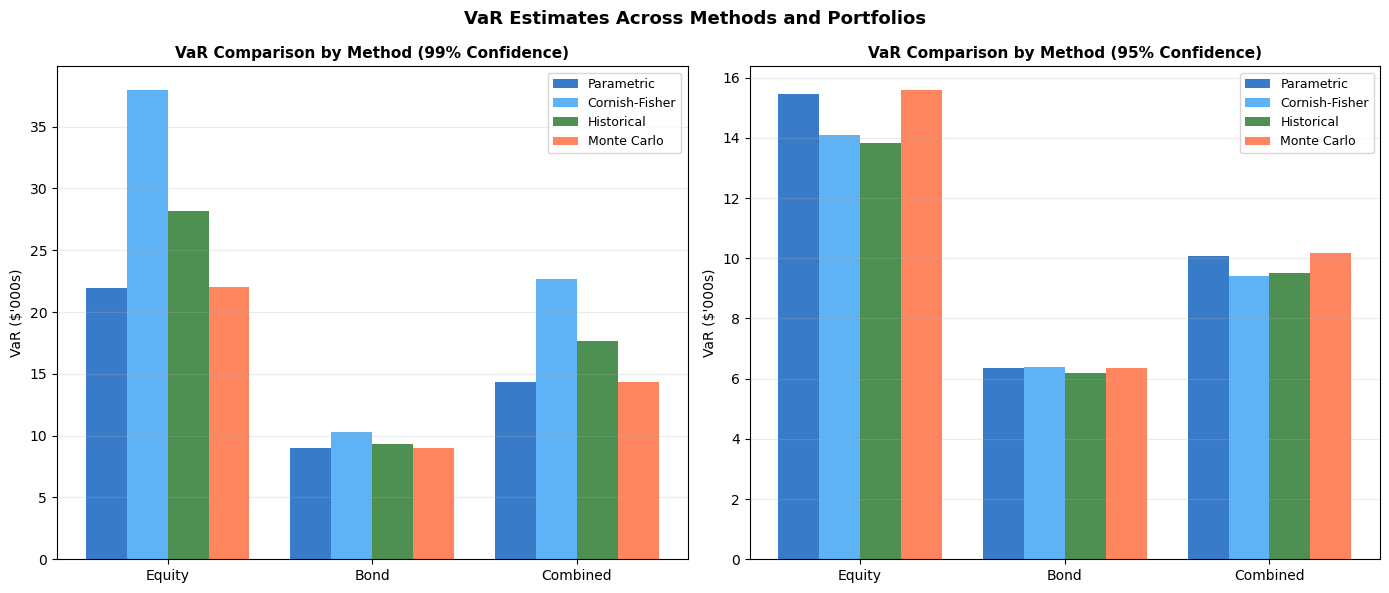

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

port_names = list(portfolios.keys())

for ax, conf in zip(axes, [0.99, 0.95]):
    methods = {
        'Parametric':      [parametric_var(portfolios[p], conf)    for p in port_names],
        'Cornish-Fisher':  [cornish_fisher_var(portfolios[p], conf) for p in port_names],
        'Historical':      [historical_var(portfolios[p], conf)    for p in port_names],
        'Monte Carlo':     [monte_carlo_var(mc_simulations[p], conf) for p in port_names],
    }

    x      = np.arange(len(port_names))
    width  = 0.2
    bar_colors = ['#1565C0', '#42A5F5', '#2E7D32', '#FF7043']

    for i, (label, vals) in enumerate(methods.items()):
        ax.bar(x + i * width, [v / 1000 for v in vals],
               width, label=label, color=bar_colors[i], alpha=0.85)

    ax.set_title(f'VaR Comparison by Method ({int(conf*100)}% Confidence)',
                 fontsize=11, fontweight='bold')
    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(port_names)
    ax.set_ylabel("VaR ($'000s)", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.25, axis='y')

plt.suptitle('VaR Estimates Across Methods and Portfolios',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('var_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Historical Simulation Expected Shortfall (99%)

In [18]:
def historical_es(returns, confidence=0.99, investment=1_000_000):
    r         = np.array(returns, dtype=float)
    r         = r[~np.isnan(r)]
    # Find the cutoff — returns worse than this are in the tail
    threshold = np.percentile(r, (1 - confidence) * 100)
    tail      = r[r < threshold]
    # ES is the average of those tail losses (~10 worst days at 99%)
    es        = -tail.mean()
    return es * investment

print("Historical Simulation ES (99%, $1M):")
for name, ret in portfolios.items():
    print(f"  {name}: ${historical_es(ret):,.2f}")

Historical Simulation ES (99%, $1M):
  Equity: $37,160.69
  Bond: $11,414.58
  Combined: $23,825.85


## ES Comparison Chart

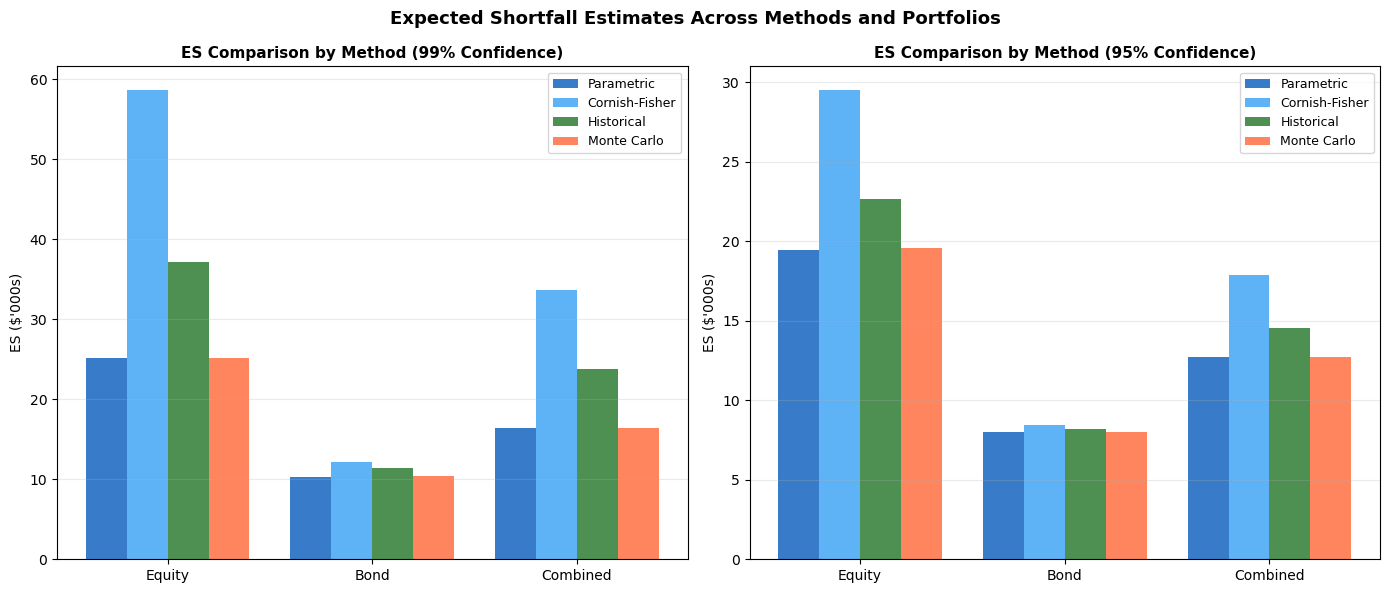

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, conf in zip(axes, [0.99, 0.95]):
    methods = {
        'Parametric':     [parametric_es(portfolios[p], conf)     for p in port_names],
        'Cornish-Fisher': [cornish_fisher_es(portfolios[p], conf)  for p in port_names],
        'Historical':     [historical_es(portfolios[p], conf)     for p in port_names],
        'Monte Carlo':    [monte_carlo_es(mc_simulations[p], conf) for p in port_names],
    }

    x      = np.arange(len(port_names))
    width  = 0.2
    bar_colors = ['#1565C0', '#42A5F5', '#2E7D32', '#FF7043']

    for i, (label, vals) in enumerate(methods.items()):
        ax.bar(x + i * width, [v / 1000 for v in vals],
               width, label=label, color=bar_colors[i], alpha=0.85)

    ax.set_title(f'ES Comparison by Method ({int(conf*100)}% Confidence)',
                 fontsize=11, fontweight='bold')
    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(port_names)
    ax.set_ylabel("ES ($'000s)", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.25, axis='y')

plt.suptitle('Expected Shortfall Estimates Across Methods and Portfolios',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('es_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Exponential Spectral Risk Measure (99%)

In [20]:
def exponential_spectral_rm(returns, gamma=0.2, n_slices=1000, investment=1_000_000):
    r = np.array(returns, dtype=float)
    r = r[~np.isnan(r)]

    # Create n_slices evenly spaced probability points across (0,1)
    # Using midpoints so we avoid the boundary issues at exactly 0 and 1
    p = np.linspace(1 / (2 * n_slices), 1 - 1 / (2 * n_slices), n_slices)
    dp = 1.0 / n_slices

    # Exponential weight function — integrates to 1 over [0,1]
    # (1-p) in exponent means weight is highest at p=0 (worst losses)
    weights = np.exp((1 - p) / gamma) / (gamma * (np.exp(1 / gamma) - 1))

    # Normalise to ensure discrete weights sum correctly
    weights = weights / weights.sum()

    # Map probability levels to empirical quantiles of the return distribution
    quantiles = np.percentile(r, p * 100)

    # Weighted average of quantiles — negative sign converts returns to losses
    srm = -np.sum(weights * quantiles)

    return srm * investment

print("Exponential Spectral Risk Measure (gamma=0.2, 1000 slices, $1M):")
for name, ret in portfolios.items():
    print(f"  {name}: ${exponential_spectral_rm(ret):,.2f}")

Exponential Spectral Risk Measure (gamma=0.2, 1000 slices, $1M):
  Equity: $9,651.47
  Bond: $4,076.99
  Combined: $6,360.59


# Sensitivity Analysis of Spectral Risk Measure


In [21]:
print("Exponential SRM Sensitivity to Gamma:")
print(f"{'Gamma':<10} {'Equity':>13} {'Bond':>13} {'Combined':>13}")
print("-" * 52)
for g in [0.1, 0.2, 0.3, 0.5]:
    row = f"{g:<10}"
    for ret in portfolios.values():
        row += f" ${exponential_spectral_rm(ret, gamma=g):>11,.2f}"
    print(row)

Exponential SRM Sensitivity to Gamma:
Gamma             Equity          Bond      Combined
----------------------------------------------------
0.1        $  14,384.92 $   5,760.10 $   9,420.46
0.2        $   9,651.47 $   4,076.99 $   6,360.59
0.3        $   7,084.45 $   3,059.87 $   4,675.79
0.5        $   4,458.94 $   1,969.31 $   2,942.73


In [22]:
print("Exponential SRM Sensitivity to n_slices (gamma=0.2):")
print(f"{'n_slices':<12} {'Equity':>13} {'Bond':>13} {'Combined':>13}")
print("-" * 52)
for n in [50, 100, 500, 1000, 2000, 5000]:
    row = f"{n:<12}"
    for ret in portfolios.values():
        row += f" ${exponential_spectral_rm(ret, gamma=0.2, n_slices=n):>11,.2f}"
    print(row)

Exponential SRM Sensitivity to n_slices (gamma=0.2):
n_slices            Equity          Bond      Combined
----------------------------------------------------
50           $   9,397.10 $   4,024.68 $   6,194.89
100          $   9,481.58 $   4,062.82 $   6,295.27
500          $   9,632.04 $   4,067.17 $   6,350.93
1000         $   9,651.47 $   4,076.99 $   6,360.59
2000         $   9,651.55 $   4,077.01 $   6,360.64
5000         $   9,651.57 $   4,077.01 $   6,360.65


## Gamma Sensitivity Chart

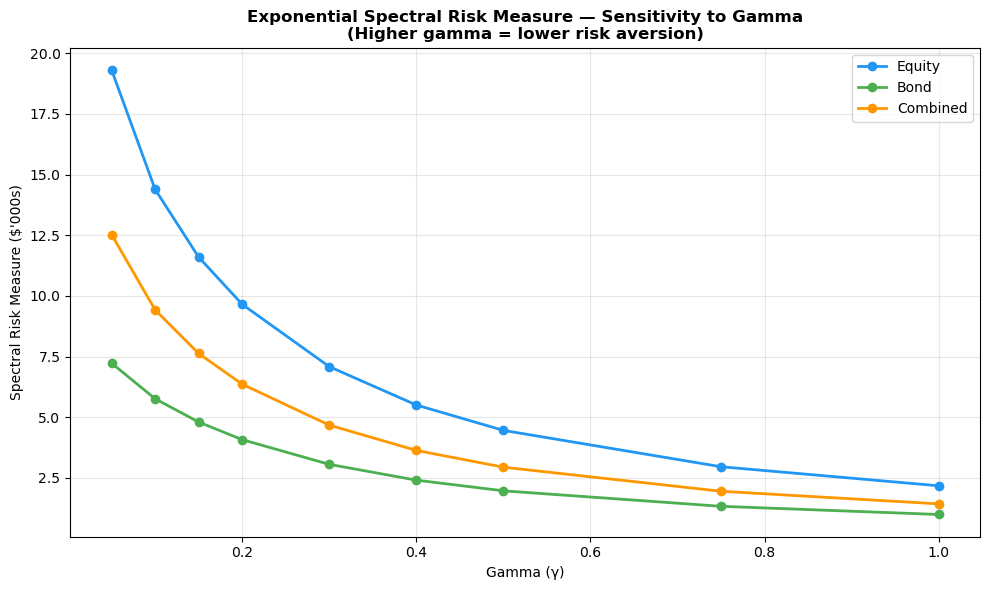

In [23]:
gammas     = [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0]
srm_values = {name: [] for name in portfolios}

for g in gammas:
    for name, ret in portfolios.items():
        srm_values[name].append(exponential_spectral_rm(ret, gamma=g) / 1000)

fig, ax = plt.subplots(figsize=(10, 6))

for name in portfolios:
    ax.plot(gammas, srm_values[name], color=colors[name],
            marker='o', linewidth=2, markersize=6, label=name)

ax.set_title('Exponential Spectral Risk Measure — Sensitivity to Gamma\n'
             '(Higher gamma = lower risk aversion)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Gamma (γ)', fontsize=10)
ax.set_ylabel("Spectral Risk Measure ($'000s)", fontsize=10)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('spectral_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

## Volatility and Maximum Drawdown

In [24]:
def volatility_measures(returns, name):
    daily_vol  = returns.std()
    annual_vol = daily_vol * np.sqrt(252)

    # Build a cumulative index starting at 100
    cum_index   = 100 * np.exp(np.cumsum(returns))
    running_max = np.maximum.accumulate(cum_index)
    drawdown    = (cum_index - running_max) / running_max
    max_dd      = drawdown.min()

    print(f"  {name}:")
    print(f"    Daily Volatility:      {daily_vol:.4%}")
    print(f"    Annualised Volatility: {annual_vol:.4%}")
    print(f"    Maximum Drawdown:      {max_dd:.4%}")

print("Volatility and Maximum Drawdown:")
for name, ret in portfolios.items():
    volatility_measures(ret, name)

Volatility and Maximum Drawdown:
  Equity:
    Daily Volatility:      0.9556%
    Annualised Volatility: 15.1693%
    Maximum Drawdown:      -22.2126%
  Bond:
    Daily Volatility:      0.3905%
    Annualised Volatility: 6.1982%
    Maximum Drawdown:      -11.5754%
  Combined:
    Daily Volatility:      0.6246%
    Annualised Volatility: 9.9159%
    Maximum Drawdown:      -17.1299%


## Drawdown Over Time

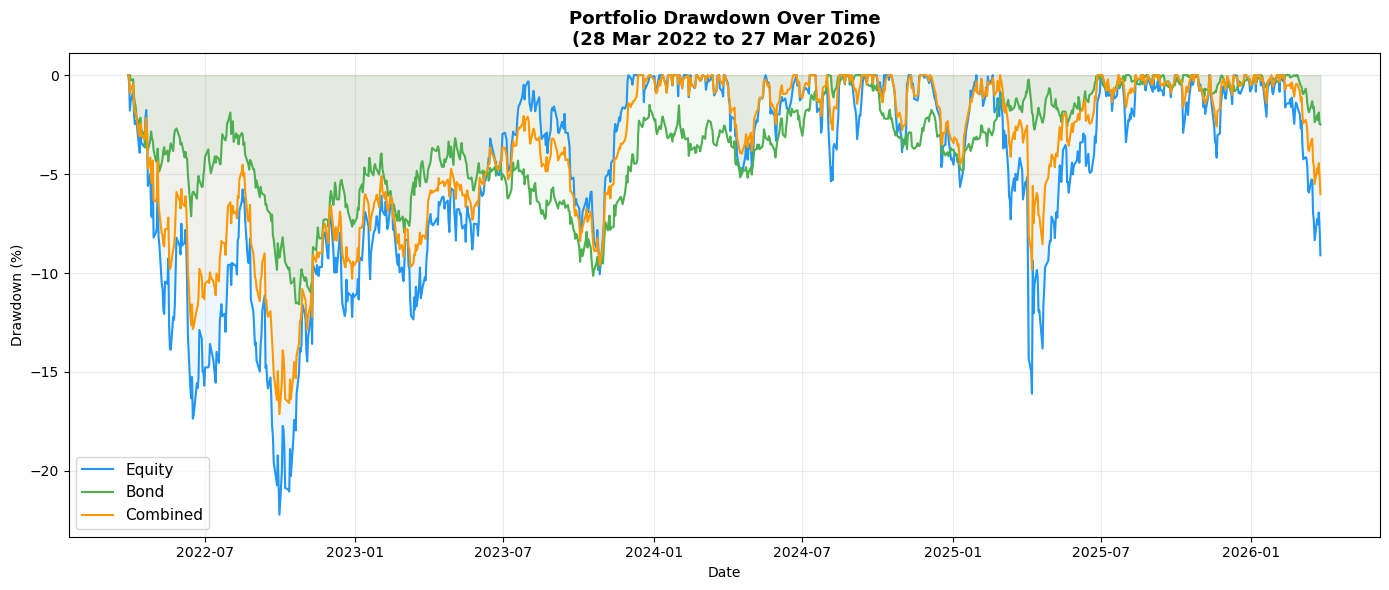

In [25]:
fig, ax = plt.subplots(figsize=(14, 6))

for name, ret in portfolios.items():
    cum      = 100 * np.exp(np.cumsum(ret))
    rmax     = np.maximum.accumulate(cum)
    drawdown = (cum - rmax) / rmax * 100
    ax.plot(ret.index, drawdown, color=colors[name],
            label=name, linewidth=1.5)
    ax.fill_between(ret.index, drawdown, 0,
                    color=colors[name], alpha=0.07)

ax.set_title('Portfolio Drawdown Over Time\n(28 Mar 2022 to 27 Mar 2026)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Date', fontsize=10)
ax.set_ylabel('Drawdown (%)', fontsize=10)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig('drawdown.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary Table

In [26]:
print("\n" + "="*72)
print("  FULL RISK ESTIMATES AS AT 27 MARCH 2026  |  $1,000,000 Investment")
print("="*72)
print(f"{'Measure':<28} {'Equity':>13} {'Bond':>13} {'Combined':>13}")
print("-"*72)

all_measures_99 = {
    'Parametric VaR (99%)':      lambda r: parametric_var(r, 0.99),
    'Parametric ES (99%)':       lambda r: parametric_es(r, 0.99),
    'Cornish-Fisher VaR (99%)':  lambda r: cornish_fisher_var(r, 0.99),
    'Cornish-Fisher ES (99%)':   lambda r: cornish_fisher_es(r, 0.99),
    'Historical VaR (99%)':      lambda r: historical_var(r, 0.99),
    'Historical ES (99%)':       lambda r: historical_es(r, 0.99),
}

for label, func in all_measures_99.items():
    row = f"{label:<28}"
    for ret in portfolios.values():
        row += f" ${func(ret):>11,.2f}"
    print(row)

row = f"{'MC VaR (99%)':<28}"
for sim in mc_simulations.values():
    row += f" ${monte_carlo_var(sim, 0.99):>11,.2f}"
print(row)

row = f"{'MC ES (99%)':<28}"
for sim in mc_simulations.values():
    row += f" ${monte_carlo_es(sim, 0.99):>11,.2f}"
print(row)

row = f"{'Exponential SRM (g=0.2)':<28}"
for ret in portfolios.values():
    row += f" ${exponential_spectral_rm(ret, gamma=0.2):>11,.2f}"
print(row)

print("-"*72)

all_measures_95 = {
    'Parametric VaR (95%)':      lambda r: parametric_var(r, 0.95),
    'Parametric ES (95%)':       lambda r: parametric_es(r, 0.95),
    'Cornish-Fisher VaR (95%)':  lambda r: cornish_fisher_var(r, 0.95),
    'Cornish-Fisher ES (95%)':   lambda r: cornish_fisher_es(r, 0.95),
    'Historical VaR (95%)':      lambda r: historical_var(r, 0.95),
    'Historical ES (95%)':       lambda r: historical_es(r, 0.95),
}

for label, func in all_measures_95.items():
    row = f"{label:<28}"
    for ret in portfolios.values():
        row += f" ${func(ret):>11,.2f}"
    print(row)

row = f"{'MC VaR (95%)':<28}"
for sim in mc_simulations.values():
    row += f" ${monte_carlo_var(sim, 0.95):>11,.2f}"
print(row)

row = f"{'MC ES (95%)':<28}"
for sim in mc_simulations.values():
    row += f" ${monte_carlo_es(sim, 0.95):>11,.2f}"
print(row)

print("="*72)

print(f"\n{'Measure':<28} {'Equity':>13} {'Bond':>13} {'Combined':>13}")
print("-"*72)

row = f"{'Daily Volatility':<28}"
for ret in portfolios.values():
    row += f"  {ret.std():>11.4%}"
print(row)

row = f"{'Annualised Volatility':<28}"
for ret in portfolios.values():
    row += f"  {ret.std()*np.sqrt(252):>11.4%}"
print(row)

row = f"{'Maximum Drawdown':<28}"
for ret in portfolios.values():
    cum  = 100 * np.exp(np.cumsum(ret))
    rmax = np.maximum.accumulate(cum)
    mdd  = ((cum - rmax) / rmax).min()
    row += f"  {mdd:>11.4%}"
print(row)

print("="*72)


  FULL RISK ESTIMATES AS AT 27 MARCH 2026  |  $1,000,000 Investment
Measure                             Equity          Bond      Combined
------------------------------------------------------------------------
Parametric VaR (99%)         $  21,964.00 $   9,017.84 $  14,345.64
Parametric ES (99%)          $  25,202.13 $  10,340.95 $  16,462.35
Cornish-Fisher VaR (99%)     $  37,977.62 $  10,328.04 $  22,706.72
Cornish-Fisher ES (99%)      $  58,651.89 $  12,100.32 $  33,702.07
Historical VaR (99%)         $  28,165.79 $   9,286.91 $  17,691.04
Historical ES (99%)          $  37,160.69 $  11,414.58 $  23,825.85
MC VaR (99%)                 $  22,034.22 $   8,972.19 $  14,376.22
MC ES (99%)                  $  25,154.18 $  10,342.79 $  16,369.04
Exponential SRM (g=0.2)      $   9,651.47 $   4,076.99 $   6,360.59
------------------------------------------------------------------------
Parametric VaR (95%)         $  15,451.80 $   6,356.93 $  10,088.71
Parametric ES (95%)          $  19

## Risk Estimates Heatmap

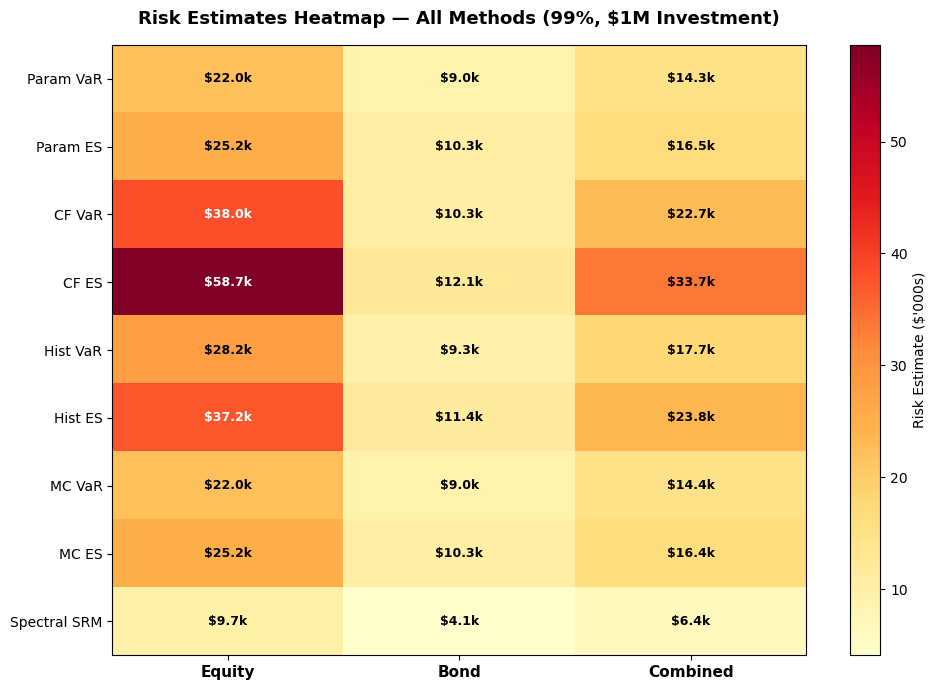

In [27]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Build the data matrix for the heatmap
measures_99 = {
    'Param VaR':   [parametric_var(portfolios[p], 0.99)     for p in portfolios],
    'Param ES':    [parametric_es(portfolios[p], 0.99)      for p in portfolios],
    'CF VaR':      [cornish_fisher_var(portfolios[p], 0.99) for p in portfolios],
    'CF ES':       [cornish_fisher_es(portfolios[p], 0.99)  for p in portfolios],
    'Hist VaR':    [historical_var(portfolios[p], 0.99)     for p in portfolios],
    'Hist ES':     [historical_es(portfolios[p], 0.99)      for p in portfolios],
    'MC VaR':      [monte_carlo_var(mc_simulations[p], 0.99) for p in portfolios],
    'MC ES':       [monte_carlo_es(mc_simulations[p], 0.99)  for p in portfolios],
    'Spectral SRM':[exponential_spectral_rm(portfolios[p])  for p in portfolios],
}

port_names   = list(portfolios.keys())
measure_names = list(measures_99.keys())
matrix        = np.array(list(measures_99.values())) / 1000  # convert to $'000s

fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(matrix, cmap='YlOrRd', aspect='auto')

ax.set_xticks(range(len(port_names)))
ax.set_xticklabels(port_names, fontsize=11, fontweight='bold')
ax.set_yticks(range(len(measure_names)))
ax.set_yticklabels(measure_names, fontsize=10)

# Annotate each cell with the dollar value
for i in range(len(measure_names)):
    for j in range(len(port_names)):
        val = matrix[i, j]
        # Use white text on dark cells, black on light cells
        text_color = 'white' if val > matrix.max() * 0.6 else 'black'
        ax.text(j, i, f'${val:,.1f}k',
                ha='center', va='center',
                fontsize=9, color=text_color, fontweight='bold')

plt.colorbar(im, ax=ax, label="Risk Estimate ($'000s)")
ax.set_title('Risk Estimates Heatmap — All Methods (99%, $1M Investment)',
             fontsize=13, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig('risk_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## Radar Chart of Portfolio Risk Profile

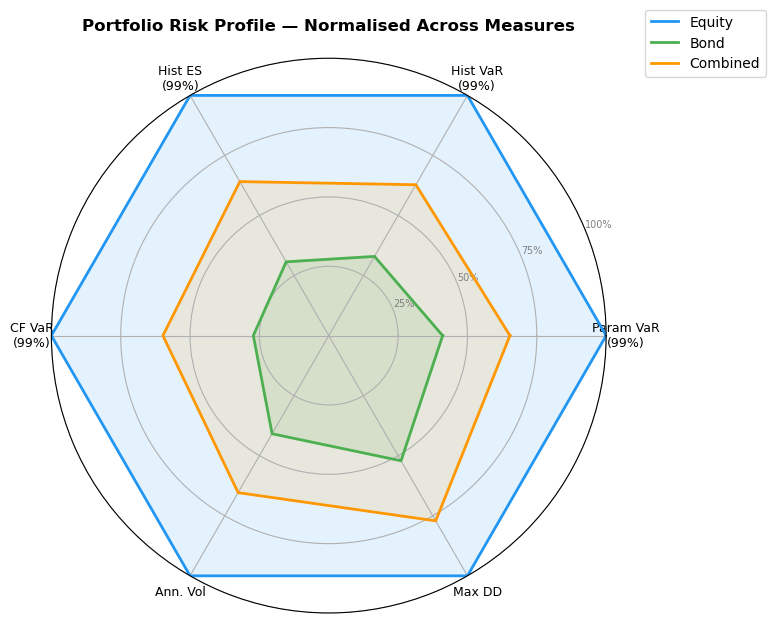

In [28]:
from matplotlib.patches import FancyArrowPatch
import matplotlib.pyplot as plt
import numpy as np

# Normalise each measure to [0,1] across portfolios for radar scaling
radar_measures = {
    'Param VaR\n(99%)':    [parametric_var(portfolios[p], 0.99)      for p in portfolios],
    'Hist VaR\n(99%)':     [historical_var(portfolios[p], 0.99)      for p in portfolios],
    'Hist ES\n(99%)':      [historical_es(portfolios[p], 0.99)       for p in portfolios],
    'CF VaR\n(99%)':       [cornish_fisher_var(portfolios[p], 0.99)  for p in portfolios],
    'Ann. Vol':            [portfolios[p].std() * np.sqrt(252) * 1_000_000 for p in portfolios],
    'Max DD':              [abs(((100*np.exp(np.cumsum(portfolios[p])) -
                             np.maximum.accumulate(100*np.exp(np.cumsum(portfolios[p])))) /
                             np.maximum.accumulate(100*np.exp(np.cumsum(portfolios[p])))).min())
                            * 1_000_000 for p in portfolios],
}

labels      = list(radar_measures.keys())
n_axes      = len(labels)
angles      = np.linspace(0, 2 * np.pi, n_axes, endpoint=False).tolist()
angles     += angles[:1]  # close the polygon

port_names  = list(portfolios.keys())
colors_list = ['#2196F3', '#4CAF50', '#FF9800']

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for idx, (name, color) in enumerate(zip(port_names, colors_list)):
    raw_vals = [radar_measures[m][idx] for m in labels]
    # Normalise by the maximum across all portfolios for each measure
    max_vals = [max(radar_measures[m]) for m in labels]
    norm_vals = [v / m if m > 0 else 0 for v, m in zip(raw_vals, max_vals)]
    norm_vals += norm_vals[:1]

    ax.plot(angles, norm_vals, color=color, linewidth=2, label=name)
    ax.fill(angles, norm_vals, color=color, alpha=0.12)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=9)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['25%', '50%', '75%', '100%'], fontsize=7, color='grey')
ax.set_ylim(0, 1)

ax.set_title('Portfolio Risk Profile — Normalised Across Measures',
             fontsize=12, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)

plt.tight_layout()
plt.savefig('risk_radar.png', dpi=150, bbox_inches='tight')
plt.show()

## Confidence Level Sensitivity

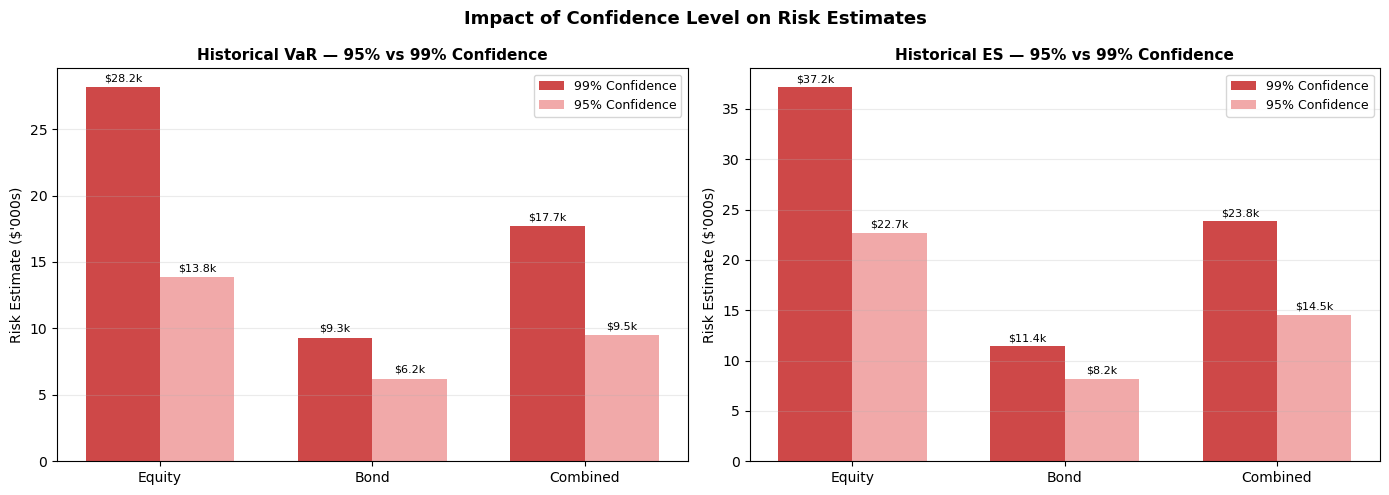

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

port_names  = list(portfolios.keys())
x           = np.arange(len(port_names))
width       = 0.35
bar_colors  = ['#2196F3', '#4CAF50', '#FF9800']

for ax, (method_name, func_99, func_95) in zip(axes, [
    ('Historical VaR',
     lambda p: historical_var(portfolios[p], 0.99),
     lambda p: historical_var(portfolios[p], 0.95)),
    ('Historical ES',
     lambda p: historical_es(portfolios[p], 0.99),
     lambda p: historical_es(portfolios[p], 0.95)),
]):
    vals_99 = [func_99(p) / 1000 for p in port_names]
    vals_95 = [func_95(p) / 1000 for p in port_names]

    bars_99 = ax.bar(x - width/2, vals_99, width,
                     label='99% Confidence', color='#C62828', alpha=0.85)
    bars_95 = ax.bar(x + width/2, vals_95, width,
                     label='95% Confidence', color='#EF9A9A', alpha=0.85)

    # Annotate bars with values
    for bar in bars_99:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'${bar.get_height():,.1f}k', ha='center', va='bottom', fontsize=8)
    for bar in bars_95:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'${bar.get_height():,.1f}k', ha='center', va='bottom', fontsize=8)

    ax.set_title(f'{method_name} — 95% vs 99% Confidence',
                 fontsize=11, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(port_names)
    ax.set_ylabel("Risk Estimate ($'000s)", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.25, axis='y')

plt.suptitle('Impact of Confidence Level on Risk Estimates',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('confidence_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Assignment Part 2

## Heading and setup

In [30]:
# ============================================================
# PART 2 — ROLLING WINDOW BACKTESTING OF VaR AND ES ESTIMATES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Assignment-required rolling window setup
estimation_start = pd.Timestamp("2022-03-28")
estimation_end   = pd.Timestamp("2024-03-29")   # initial estimation sample ends here
backtest_start   = pd.Timestamp("2024-04-02")   # next trading day after 29 Mar 2024
backtest_end     = pd.Timestamp("2026-03-27")

window_mask = (equity_portfolio.index >= estimation_start) & (equity_portfolio.index <= estimation_end)
initial_window_length = window_mask.sum()

print("PART 2 SETUP")
print("-" * 50)
print(f"Initial estimation window: {estimation_start.date()} to {estimation_end.date()}")
print(f"Backtest period:           {backtest_start.date()} to {backtest_end.date()}")
print(f"Initial rolling window length: {initial_window_length} observations")

PART 2 SETUP
--------------------------------------------------
Initial estimation window: 2022-03-28 to 2024-03-29
Backtest period:           2024-04-02 to 2026-03-27
Initial rolling window length: 500 observations


## Backtesting helper function

In [31]:
# -----------------------------
# Rolling backtesting functions
# -----------------------------

def rolling_parametric_var(returns_window, confidence=0.99, investment=1_000_000):
    mu    = returns_window.mean()
    sigma = returns_window.std()
    z     = stats.norm.ppf(confidence)
    var   = (-mu + z * sigma) * investment
    return var
    
def rolling_parametric_es(returns_window, confidence=0.99, investment=1_000_000):
    mu    = returns_window.mean()
    sigma = returns_window.std()
    alpha = 1 - confidence
    z     = stats.norm.ppf(confidence)
    es    = (-mu + sigma * stats.norm.pdf(z) / alpha) * investment
    return es

def rolling_historical_var(returns_window, confidence=0.99, investment=1_000_000):
    r   = np.array(returns_window, dtype=float)
    r   = r[~np.isnan(r)]
    var = -np.percentile(r, (1 - confidence) * 100)
    return var * investment

def rolling_historical_es(returns_window, confidence=0.99, investment=1_000_000):
    r         = np.array(returns_window, dtype=float)
    r         = r[~np.isnan(r)]
    threshold = np.percentile(r, (1 - confidence) * 100)
    tail      = r[r < threshold]
    es        = -tail.mean()
    return es * investment

def rolling_cornish_fisher_var(returns_window, confidence=0.99, investment=1_000_000):
    mu    = returns_window.mean()
    sigma = returns_window.std()
    s     = stats.skew(returns_window)
    k     = stats.kurtosis(returns_window)
    z     = stats.norm.ppf(confidence)

    z_cf = (z
            + (z**2 - 1) * s / 6
            + (z**3 - 3*z) * k / 24
            - (2*z**3 - 5*z) * s**2 / 36)

    var = (-mu + z_cf * sigma) * investment
    return var

def rolling_cornish_fisher_es(returns_window, confidence=0.99, investment=1_000_000,
                               n_grid=500):
    mu    = returns_window.mean()
    sigma = returns_window.std()
    s     = stats.skew(returns_window)
    k     = stats.kurtosis(returns_window)
    alpha = 1 - confidence

    # Consistent with Part 1 CF ES — integrate over the left tail [0, alpha]
    p_tail    = np.linspace(1e-6, alpha, n_grid)
    z_vals    = stats.norm.ppf(np.clip(p_tail, 1e-6, 1 - 1e-6))
    z_cf_vals = (z_vals
                 + (z_vals**2 - 1) * s / 6
                 + (z_vals**3 - 3*z_vals) * k / 24
                 - (2*z_vals**3 - 5*z_vals) * s**2 / 36)

    quantiles = mu + z_cf_vals * sigma
    es        = -np.trapezoid(quantiles, p_tail) / alpha
    return abs(es) * investment

def rolling_monte_carlo_var(returns_window, confidence=0.99, investment=1_000_000,
                            n_sims=10000):
    mu    = returns_window.mean()
    sigma = returns_window.std()
    sims  = np.random.normal(mu, sigma, n_sims)
    var   = -np.percentile(sims, (1 - confidence) * 100)
    return var * investment


def rolling_monte_carlo_es(returns_window, confidence=0.99, investment=1_000_000,
                           n_sims=10000):
    mu        = returns_window.mean()
    sigma     = returns_window.std()
    sims      = np.random.normal(mu, sigma, n_sims)
    threshold = np.percentile(sims, (1 - confidence) * 100)
    tail      = sims[sims < threshold]
    es        = -tail.mean()
    return es * investment

## Method dictionaries

In [32]:
# -----------------------------------
# Dictionaries of VaR and ES methods
# -----------------------------------

var_methods = {
    'Parametric VaR':     rolling_parametric_var,
    'Cornish-Fisher VaR': rolling_cornish_fisher_var,
    'Historical VaR':     rolling_historical_var,
    'Monte Carlo VaR':    rolling_monte_carlo_var,
}

es_methods = {
    'Parametric ES':      rolling_parametric_es,
    'Cornish-Fisher ES':  rolling_cornish_fisher_es,
    'Historical ES':      rolling_historical_es,
    'Monte Carlo ES':     rolling_monte_carlo_es,
}

confidence_levels = [0.99, 0.95]

## Rolling forecast engine

In [33]:
# -----------------------------------
# Rolling one-day-ahead forecast loop
# -----------------------------------

def generate_rolling_backtest_forecasts(portfolio_returns,
                                        var_methods,
                                        es_methods,
                                        confidence_levels=[0.99, 0.95],
                                        investment=1_000_000):
    
    portfolio_returns = portfolio_returns.sort_index().copy()

    # Restrict to the full assignment sample
    portfolio_returns = portfolio_returns.loc[
        (portfolio_returns.index >= estimation_start) &
        (portfolio_returns.index <= backtest_end)
    ]

    forecast_store = {}

    for conf in confidence_levels:
        var_df = pd.DataFrame(index=portfolio_returns.loc[backtest_start:backtest_end].index)
        es_df  = pd.DataFrame(index=portfolio_returns.loc[backtest_start:backtest_end].index)

        for t in range(initial_window_length, len(portfolio_returns)):
            forecast_date = portfolio_returns.index[t]
            
            # Only generate forecasts during the backtest period
            if forecast_date < backtest_start or forecast_date > backtest_end:
                continue

            # Rolling window: fixed width equal to the initial sample length
            estimation_window = portfolio_returns.iloc[t - initial_window_length:t]

            # VaR forecasts
            for method_name, method_func in var_methods.items():
                var_df.loc[forecast_date, method_name] = method_func(
                    estimation_window,
                    confidence=conf,
                    investment=investment
                )

            # ES forecasts
            for method_name, method_func in es_methods.items():
                es_df.loc[forecast_date, method_name] = method_func(
                    estimation_window,
                    confidence=conf,
                    investment=investment
                )

        # Realised one-day P&L for backtest evaluation
        realised_pnl = portfolio_returns.loc[backtest_start:backtest_end] * investment

        forecast_store[conf] = {
            'VaR': var_df,
            'ES': es_df,
            'Realised PnL': realised_pnl
        }

    return forecast_store

## Run the rolling backtests for all three portfolios

In [34]:
# -----------------------------------
# Generate rolling forecasts
# -----------------------------------

np.random.seed(42)

rolling_results = {}

for name, ret in portfolios.items():
    print(f"Generating rolling forecasts for {name} portfolio...")
    rolling_results[name] = generate_rolling_backtest_forecasts(
        portfolio_returns=ret,
        var_methods=var_methods,
        es_methods=es_methods,
        confidence_levels=confidence_levels,
        investment=investment
    )

print("\nDone.")

Generating rolling forecasts for Equity portfolio...
Generating rolling forecasts for Bond portfolio...
Generating rolling forecasts for Combined portfolio...

Done.


## Quick inspection tables

In [35]:
# -----------------------------------
# Inspect the first few forecast rows
# -----------------------------------

for portfolio_name in rolling_results:
    print("\n" + "=" * 80)
    print(f"{portfolio_name.upper()} PORTFOLIO — 99% VaR FORECASTS (HEAD)")
    print("=" * 80)
    display(rolling_results[portfolio_name][0.99]['VaR'].head())

    print(f"\n{portfolio_name.upper()} PORTFOLIO — 99% ES FORECASTS (HEAD)")
    display(rolling_results[portfolio_name][0.99]['ES'].head())

    print(f"\n{portfolio_name.upper()} PORTFOLIO — REALISED P&L (HEAD)")
    display(rolling_results[portfolio_name][0.99]['Realised PnL'].head())


EQUITY PORTFOLIO — 99% VaR FORECASTS (HEAD)


,Parametric VaR,Cornish-Fisher VaR,Historical VaR,Monte Carlo VaR
2024-04-02,23727.519011,26860.722334,31050.547997,23667.712008
2024-04-03,23747.539109,26876.943495,31050.547997,23498.943480
2024-04-04,23676.349558,26858.281429,31050.547997,23946.872125
2024-04-05,23753.752846,26929.759857,31050.547997,23168.089357
2024-04-08,23755.515961,26913.008219,31050.547997,23882.654577



EQUITY PORTFOLIO — 99% ES FORECASTS (HEAD)


,Parametric ES,Cornish-Fisher ES,Historical ES,Monte Carlo ES
2024-04-02,27218.722816,39552.852677,35982.923531,27890.074486
2024-04-03,27240.411899,39517.196148,35982.923531,27797.545295
2024-04-04,27162.326468,39602.218819,35982.923531,27938.144369
2024-04-05,27245.578963,39504.696510,35982.923531,27386.660915
2024-04-08,27248.345130,39491.866335,35982.923531,27051.143319



EQUITY PORTFOLIO — REALISED P&L (HEAD)


...

,Parametric VaR,Cornish-Fisher VaR,Historical VaR,Monte Carlo VaR
2024-04-02,15916.227882,19142.124821,20876.187625,16271.660472
2024-04-03,15933.433269,19159.160307,20876.187625,16236.472323
2024-04-04,15895.060651,19145.171606,20876.187625,15900.597095
2024-04-05,15931.333178,19181.182087,20876.187625,15515.793937
2024-04-08,15931.473558,19186.722880,20876.187625,15825.158714



COMBINED PORTFOLIO — 99% ES FORECASTS (HEAD)


,Parametric ES,Cornish-Fisher ES,Historical ES,Monte Carlo ES
2024-04-02,18252.159408,26683.772825,23690.98883,18036.073293
2024-04-03,18270.644058,26649.817876,23690.98883,18282.912941
2024-04-04,18228.766088,26707.187151,23690.98883,17728.333929
2024-04-05,18267.653680,26645.788442,23690.98883,18561.642297
2024-04-08,18267.594096,26647.365441,23690.98883,18851.703757



COMBINED PORTFOLIO — REALISED P&L (HEAD)


2024-04-02   -5074.016835
2024-04-03   -1276.844930
2024-04-04   -7359.920974
2024-04-05    2411.897618
2024-04-08    -931.811873
dtype: float64

## Add VaR breach indicators

In [36]:
# -----------------------------------
# Construct VaR breach indicator series
# -----------------------------------

for portfolio_name in rolling_results:
    for conf in confidence_levels:
        realised_pnl = rolling_results[portfolio_name][conf]['Realised PnL']
        var_df       = rolling_results[portfolio_name][conf]['VaR']

        breach_df = pd.DataFrame(index=var_df.index)

        for col in var_df.columns:
            # Breach when realised P&L is more negative than minus VaR
            breach_df[col] = (realised_pnl < -var_df[col]).astype(int)

        rolling_results[portfolio_name][conf]['VaR Breaches'] = breach_df

## Summary of breach counts

In [37]:
# -----------------------------------
# Summary table: number of VaR breaches
# -----------------------------------

for conf in confidence_levels:
    print("\n" + "=" * 90)
    print(f"NUMBER OF VaR BREACHES | CONFIDENCE LEVEL = {int(conf * 100)}%")
    print("=" * 90)

    summary = pd.DataFrame()

    for portfolio_name in rolling_results:
        breaches = rolling_results[portfolio_name][conf]['VaR Breaches'].sum()
        summary[portfolio_name] = breaches

    display(summary.T)


NUMBER OF VaR BREACHES | CONFIDENCE LEVEL = 99%


,Parametric VaR,Cornish-Fisher VaR,Historical VaR,Monte Carlo VaR
Equity,11,7,10,11
Bond,3,2,3,3
Combined,9,5,8,9



NUMBER OF VaR BREACHES | CONFIDENCE LEVEL = 95%


,Parametric VaR,Cornish-Fisher VaR,Historical VaR,Monte Carlo VaR
Equity,22,29,26,22
Bond,12,12,9,11
Combined,24,26,25,24


## Clean visualisation of backtest paths

In [38]:
# -----------------------------------
# Visualise realised P&L against VaR
# -----------------------------------

def plot_var_backtest(portfolio_name, confidence=0.99):
    results      = rolling_results[portfolio_name][confidence]
    realised_pnl = results['Realised PnL']
    var_df       = results['VaR']
    breaches_df  = results['VaR Breaches']

    fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True)
    axes = axes.flatten()

    method_colors = {
        'Parametric VaR': '#1f77b4',
        'Cornish-Fisher VaR': '#d62728',
        'Historical VaR': '#2ca02c',
        'Monte Carlo VaR': '#9467bd'
    }

    for ax, method in zip(axes, var_df.columns):
        ax.plot(realised_pnl.index, realised_pnl / 1000,
                color='black', linewidth=1.0, alpha=0.75,
                label='Realised P&L')

        ax.plot(var_df.index, -var_df[method] / 1000,
                color=method_colors[method], linewidth=1.8,
                label=f'{method}')

        breach_dates = breaches_df.index[breaches_df[method] == 1]
        breach_vals  = realised_pnl.loc[breach_dates] / 1000

        ax.scatter(breach_dates, breach_vals,
                   color='red', s=28, zorder=5,
                   label='Breach')

        ax.axhline(0, color='grey', linewidth=0.7, linestyle='--', alpha=0.7)
        ax.set_title(f'{method} — {portfolio_name}', fontsize=11, fontweight='bold')
        ax.set_ylabel('P&L / VaR ($000)', fontsize=9)
        ax.grid(True, alpha=0.25)
        ax.legend(fontsize=8)

    fig.suptitle(f'VaR Backtesting: Realised One-Day P&L vs Forecast VaR\n'
                 f'{portfolio_name} Portfolio ({int(confidence * 100)}% Confidence)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

## Run the plots

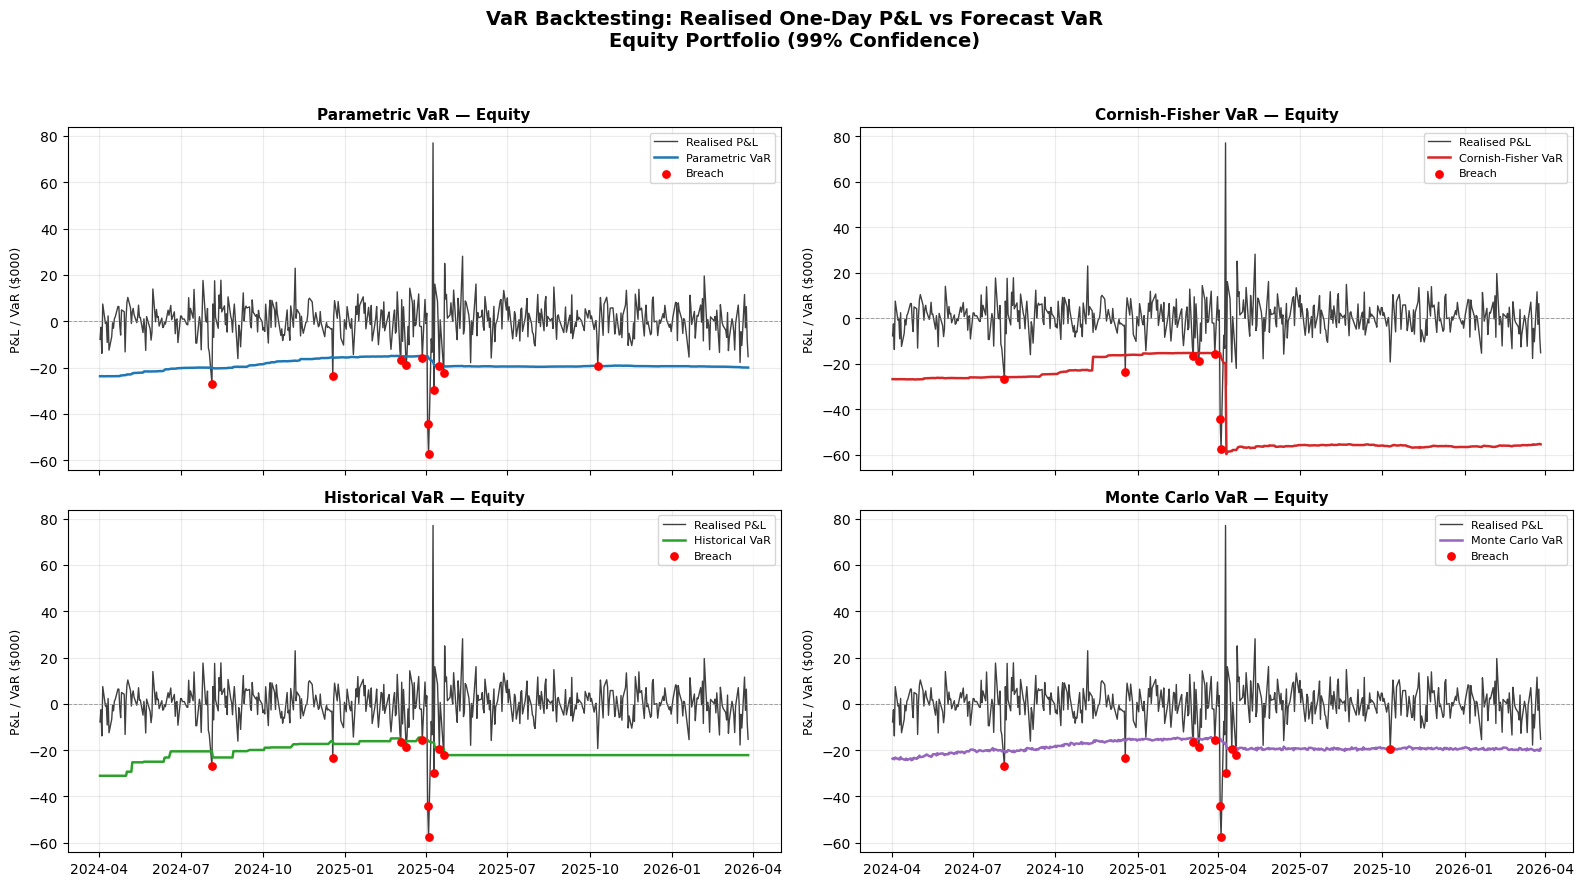

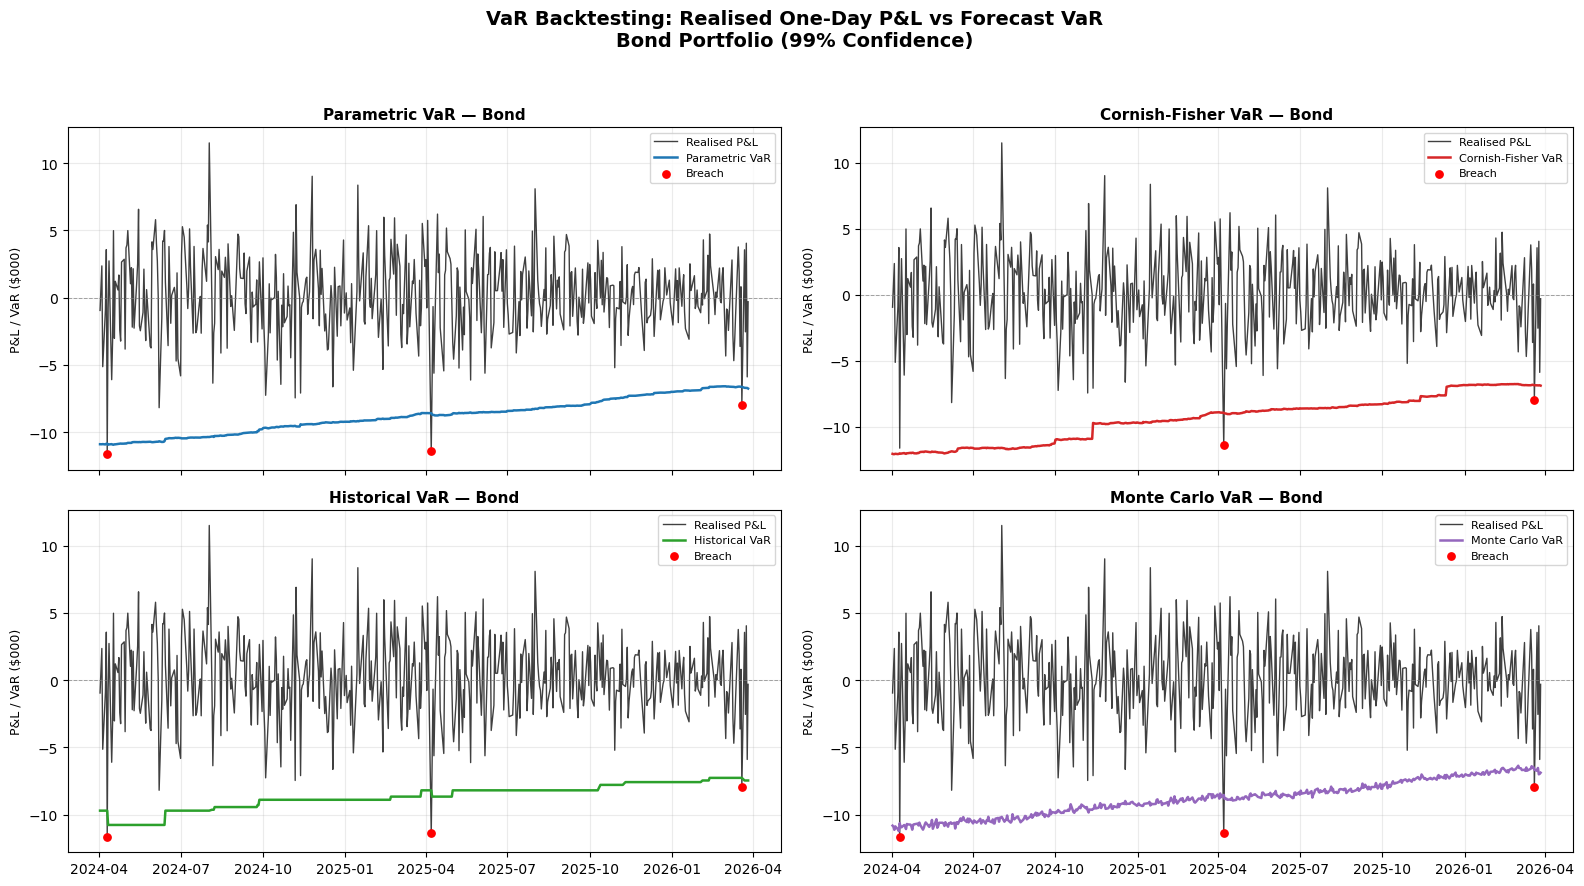

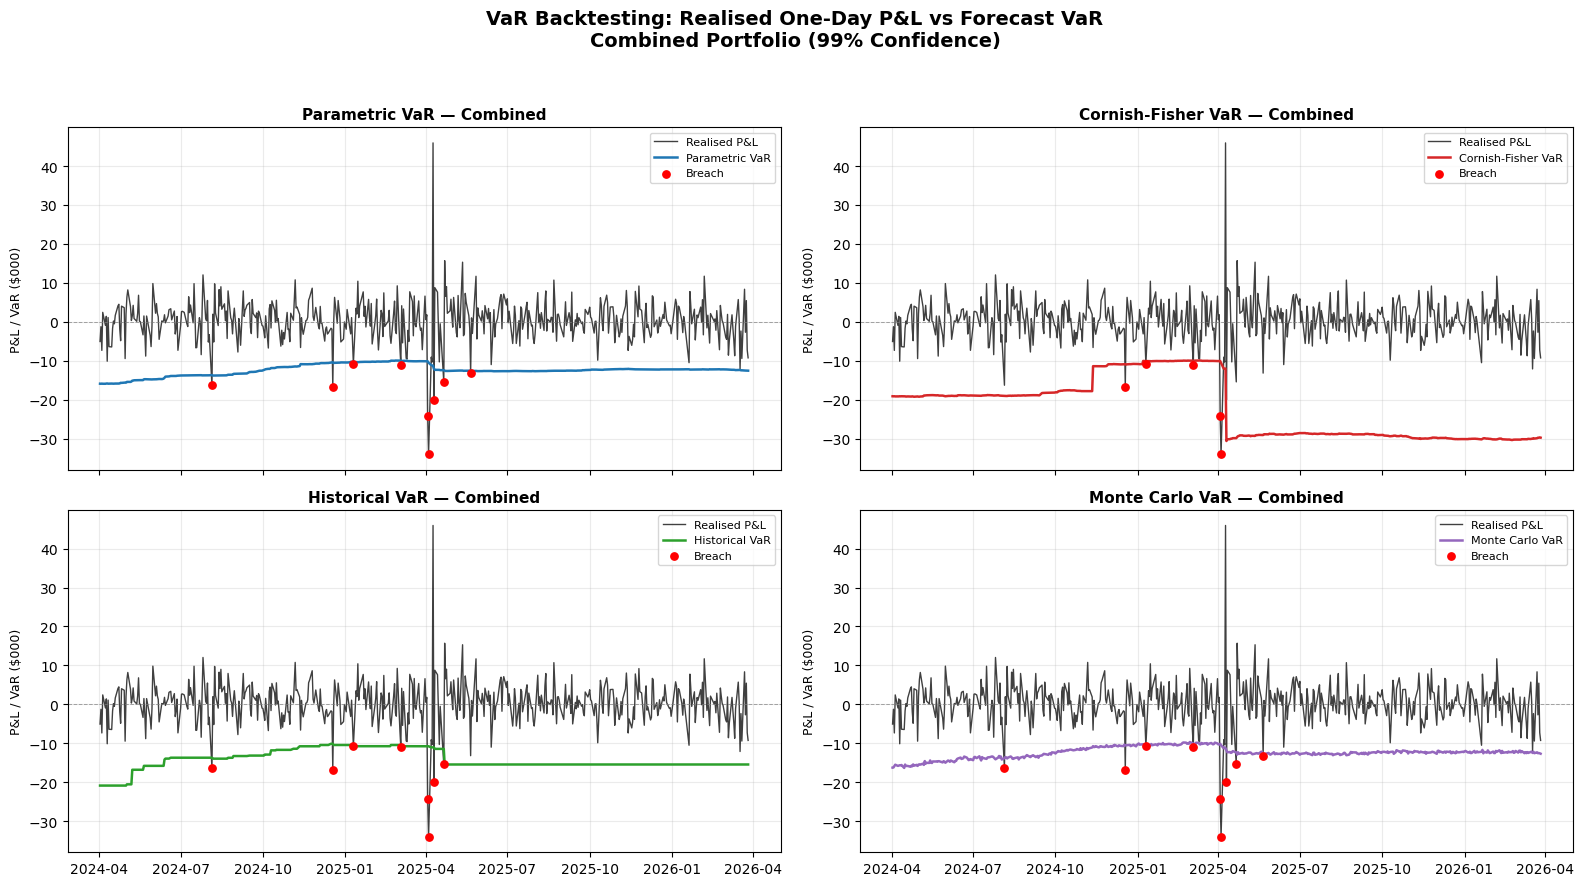

In [39]:
plot_var_backtest('Equity', confidence=0.99)
plot_var_backtest('Bond', confidence=0.99)
plot_var_backtest('Combined', confidence=0.99)

## Intro heading

In [40]:
# ============================================================
# PART 2 — FORMAL VaR BACKTESTING
# Kupiec (1995) and Christoffersen (1998) tests
# ============================================================

from scipy.stats import chi2

## Kupiec test function

In [41]:
# -----------------------------------
# Kupiec Unconditional Coverage Test
# -----------------------------------

def kupiec_test(breach_series, confidence=0.99):
    """
    Kupiec proportion-of-failures test for VaR backtesting.
    
    H0: observed breach rate = expected breach rate
    """
    breaches = np.asarray(breach_series).astype(int)
    n = len(breaches)
    x = breaches.sum()
    
    alpha = 1 - confidence
    
    # Handle edge cases carefully
    if n == 0:
        return {
            'n_obs': 0,
            'n_breaches': 0,
            'expected_rate': alpha,
            'observed_rate': np.nan,
            'LR_uc': np.nan,
            'p_value': np.nan,
            'reject_5pct': np.nan
        }
    
    pi_hat = x / n

    # Safe likelihood terms
    if x == 0:
        logL_null = (n - x) * np.log(1 - alpha)
        logL_alt  = (n - x) * np.log(1 - pi_hat) if pi_hat < 1 else -np.inf
    elif x == n:
        logL_null = x * np.log(alpha)
        logL_alt  = x * np.log(pi_hat) if pi_hat > 0 else -np.inf
    else:
        logL_null = x * np.log(alpha) + (n - x) * np.log(1 - alpha)
        logL_alt  = x * np.log(pi_hat) + (n - x) * np.log(1 - pi_hat)

    LR_uc = -2 * (logL_null - logL_alt)
    p_value = 1 - chi2.cdf(LR_uc, df=1)

    return {
        'n_obs': n,
        'n_breaches': int(x),
        'expected_rate': alpha,
        'observed_rate': pi_hat,
        'LR_uc': LR_uc,
        'p_value': p_value,
        'reject_5pct': p_value < 0.05
    }

## Christoffersen independence test

In [42]:
# -----------------------------------
# Christoffersen Independence Test
# -----------------------------------

def christoffersen_independence_test(breach_series):
    """
    Christoffersen independence test.
    
    H0: breaches are independent over time
    """
    breaches = np.asarray(breach_series).astype(int)

    if len(breaches) < 2:
        return {
            'n00': np.nan, 'n01': np.nan, 'n10': np.nan, 'n11': np.nan,
            'pi01': np.nan, 'pi11': np.nan,
            'LR_ind': np.nan, 'p_value': np.nan,
            'reject_5pct': np.nan
        }

    n00 = n01 = n10 = n11 = 0

    for i in range(1, len(breaches)):
        prev_breach = breaches[i - 1]
        curr_breach = breaches[i]

        if prev_breach == 0 and curr_breach == 0:
            n00 += 1
        elif prev_breach == 0 and curr_breach == 1:
            n01 += 1
        elif prev_breach == 1 and curr_breach == 0:
            n10 += 1
        elif prev_breach == 1 and curr_breach == 1:
            n11 += 1

    # Transition probabilities
    pi01 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0
    pi    = (n01 + n11) / (n00 + n01 + n10 + n11)

    # Likelihood under null (independent Bernoulli)
    logL_null = 0
    if (n00 + n10) > 0 and (1 - pi) > 0:
        logL_null += (n00 + n10) * np.log(1 - pi)
    if (n01 + n11) > 0 and pi > 0:
        logL_null += (n01 + n11) * np.log(pi)

    # Likelihood under alternative (Markov dependence)
    logL_alt = 0
    if n00 > 0 and (1 - pi01) > 0:
        logL_alt += n00 * np.log(1 - pi01)
    if n01 > 0 and pi01 > 0:
        logL_alt += n01 * np.log(pi01)
    if n10 > 0 and (1 - pi11) > 0:
        logL_alt += n10 * np.log(1 - pi11)
    if n11 > 0 and pi11 > 0:
        logL_alt += n11 * np.log(pi11)

    LR_ind = -2 * (logL_null - logL_alt)
    p_value = 1 - chi2.cdf(LR_ind, df=1)

    return {
        'n00': n00, 'n01': n01, 'n10': n10, 'n11': n11,
        'pi01': pi01, 'pi11': pi11,
        'LR_ind': LR_ind,
        'p_value': p_value,
        'reject_5pct': p_value < 0.05
    }

## Christoffersen conditional coverage test

In [43]:
# -----------------------------------
# Christoffersen Conditional Coverage
# -----------------------------------

def christoffersen_conditional_coverage_test(breach_series, confidence=0.99):
    """
    Christoffersen conditional coverage test.
    
    H0: correct breach frequency AND independence
    """
    kupiec_res = kupiec_test(breach_series, confidence=confidence)
    ind_res    = christoffersen_independence_test(breach_series)

    LR_uc  = kupiec_res['LR_uc']
    LR_ind = ind_res['LR_ind']
    LR_cc  = LR_uc + LR_ind

    p_value = 1 - chi2.cdf(LR_cc, df=2)

    return {
        'LR_cc': LR_cc,
        'p_value': p_value,
        'reject_5pct': p_value < 0.05
    }

## Run all VaR backtests

In [44]:
# -----------------------------------
# Run formal VaR backtests
# -----------------------------------

var_backtest_results = {}

for portfolio_name in rolling_results:
    var_backtest_results[portfolio_name] = {}

    for conf in confidence_levels:
        breach_df = rolling_results[portfolio_name][conf]['VaR Breaches']

        results_list = []

        for method in breach_df.columns:
            breaches = breach_df[method].dropna().astype(int)

            kupiec_res = kupiec_test(breaches, confidence=conf)
            ind_res    = christoffersen_independence_test(breaches)
            cc_res     = christoffersen_conditional_coverage_test(breaches, confidence=conf)

            row = {
                'Method': method,
                'Confidence': conf,
                'Observations': kupiec_res['n_obs'],
                'Breaches': kupiec_res['n_breaches'],
                'Expected Breach Rate': kupiec_res['expected_rate'],
                'Observed Breach Rate': kupiec_res['observed_rate'],

                'Kupiec LR': kupiec_res['LR_uc'],
                'Kupiec p-value': kupiec_res['p_value'],
                'Kupiec Reject 5%': kupiec_res['reject_5pct'],

                'Independence LR': ind_res['LR_ind'],
                'Independence p-value': ind_res['p_value'],
                'Independence Reject 5%': ind_res['reject_5pct'],

                'Conditional Coverage LR': cc_res['LR_cc'],
                'Conditional Coverage p-value': cc_res['p_value'],
                'Conditional Coverage Reject 5%': cc_res['reject_5pct']
            }

            results_list.append(row)

        var_backtest_results[portfolio_name][conf] = pd.DataFrame(results_list)

## Display raw formal test results

In [45]:
# -----------------------------------
# Display full VaR backtesting output
# -----------------------------------

for conf in confidence_levels:
    print("\n" + "=" * 110)
    print(f"FORMAL VaR BACKTEST RESULTS | CONFIDENCE LEVEL = {int(conf * 100)}%")
    print("=" * 110)

    for portfolio_name in var_backtest_results:
        print(f"\n{portfolio_name.upper()} PORTFOLIO")
        display(var_backtest_results[portfolio_name][conf])


FORMAL VaR BACKTEST RESULTS | CONFIDENCE LEVEL = 99%

EQUITY PORTFOLIO


,Method,Confidence,Observations,Breaches,Expected Breach Rate,Observed Breach Rate,Kupiec LR,Kupiec p-value,Kupiec Reject 5%,Independence LR,Independence p-value,Independence Reject 5%,Conditional Coverage LR,Conditional Coverage p-value,Conditional Coverage Reject 5%
0,Parametric VaR,0.99,499,11,0.01,0.022044,5.443520,0.019641,True,1.425909,0.232433,False,6.869429,0.032235,True
1,Cornish-Fisher VaR,0.99,499,7,0.01,0.014028,0.726829,0.393913,False,3.082577,0.079135,False,3.809406,0.148867,False
2,Historical VaR,0.99,499,10,0.01,0.020040,3.933965,0.047320,True,1.747858,0.186146,False,5.681823,0.058372,False
3,Monte Carlo VaR,0.99,499,11,0.01,0.022044,5.443520,0.019641,True,1.425909,0.232433,False,6.869429,0.032235,True



BOND PORTFOLIO


,Method,Confidence,Observations,Breaches,Expected Breach Rate,Observed Breach Rate,Kupiec LR,Kupiec p-value,Kupiec Reject 5%,Independence LR,Independence p-value,Independence Reject 5%,Conditional Coverage LR,Conditional Coverage p-value,Conditional Coverage Reject 5%
0,Parametric VaR,0.99,499,3,0.01,0.006012,0.935064,0.333551,False,0.036364,0.848766,False,0.971428,0.615258,False
1,Cornish-Fisher VaR,0.99,499,2,0.01,0.004008,2.340906,0.126016,False,0.016129,0.898940,False,2.357035,0.307735,False
2,Historical VaR,0.99,499,3,0.01,0.006012,0.935064,0.333551,False,0.036364,0.848766,False,0.971428,0.615258,False
3,Monte Carlo VaR,0.99,499,3,0.01,0.006012,0.935064,0.333551,False,0.036364,0.848766,False,0.971428,0.615258,False



COMBINED PORTFOLIO


...

,Method,Confidence,Observations,Breaches,Expected Breach Rate,Observed Breach Rate,Kupiec LR,Kupiec p-value,Kupiec Reject 5%,Independence LR,Independence p-value,Independence Reject 5%,Conditional Coverage LR,Conditional Coverage p-value,Conditional Coverage Reject 5%
0,Parametric VaR,0.95,499,22,0.05,0.044088,0.381740,0.536674,False,3.339248,0.067646,False,3.720987,0.155596,False
1,Cornish-Fisher VaR,0.95,499,29,0.05,0.058116,0.659176,0.416851,False,5.375138,0.020426,True,6.034314,0.048940,True
2,Historical VaR,0.95,499,26,0.05,0.052104,0.045909,0.830342,False,4.210171,0.040182,True,4.256080,0.119070,False
3,Monte Carlo VaR,0.95,499,22,0.05,0.044088,0.381740,0.536674,False,3.339248,0.067646,False,3.720987,0.155596,False



BOND PORTFOLIO


,Method,Confidence,Observations,Breaches,Expected Breach Rate,Observed Breach Rate,Kupiec LR,Kupiec p-value,Kupiec Reject 5%,Independence LR,Independence p-value,Independence Reject 5%,Conditional Coverage LR,Conditional Coverage p-value,Conditional Coverage Reject 5%
0,Parametric VaR,0.95,499,12,0.05,0.024048,8.683375,0.003211,True,0.592653,0.441395,False,9.276028,0.009677,True
1,Cornish-Fisher VaR,0.95,499,12,0.05,0.024048,8.683375,0.003211,True,0.592653,0.441395,False,9.276028,0.009677,True
2,Historical VaR,0.95,499,9,0.05,0.018036,14.077052,0.000175,True,0.331307,0.564890,False,14.408359,0.000743,True
3,Monte Carlo VaR,0.95,499,11,0.05,0.022044,10.289014,0.001338,True,0.496962,0.480838,False,10.785976,0.004548,True



COMBINED PORTFOLIO


,Method,Confidence,Observations,Breaches,Expected Breach Rate,Observed Breach Rate,Kupiec LR,Kupiec p-value,Kupiec Reject 5%,Independence LR,Independence p-value,Independence Reject 5%,Conditional Coverage LR,Conditional Coverage p-value,Conditional Coverage Reject 5%
0,Parametric VaR,0.95,499,24,0.05,0.048096,0.038543,0.844357,False,5.283732,0.021526,True,5.322275,0.069869,False
1,Cornish-Fisher VaR,0.95,499,26,0.05,0.052104,0.045909,0.830342,False,7.262769,0.007040,True,7.308677,0.025879,True
2,Historical VaR,0.95,499,25,0.05,0.050100,0.000105,0.991808,False,4.726377,0.029703,True,4.726482,0.094115,False
3,Monte Carlo VaR,0.95,499,24,0.05,0.048096,0.038543,0.844357,False,5.283732,0.021526,True,5.322275,0.069869,False


## Clean summary table for report use

In [46]:
# -----------------------------------
# Compact summary tables
# -----------------------------------

def create_var_backtest_summary(confidence=0.99):
    summary_rows = []

    for portfolio_name in var_backtest_results:
        df = var_backtest_results[portfolio_name][confidence]

        for _, row in df.iterrows():
            summary_rows.append({
                'Portfolio': portfolio_name,
                'Method': row['Method'],
                'Obs': int(row['Observations']),
                'Breaches': int(row['Breaches']),
                'Observed Rate': round(row['Observed Breach Rate'], 4),
                'Expected Rate': round(row['Expected Breach Rate'], 4),
                'Kupiec p': round(row['Kupiec p-value'], 4),
                'Independence p': round(row['Independence p-value'], 4),
                'Conditional Coverage p': round(row['Conditional Coverage p-value'], 4),
                'Kupiec Pass?': 'Pass' if not row['Kupiec Reject 5%'] else 'Fail',
                'Independence Pass?': 'Pass' if not row['Independence Reject 5%'] else 'Fail',
                'CC Pass?': 'Pass' if not row['Conditional Coverage Reject 5%'] else 'Fail'
            })

    return pd.DataFrame(summary_rows)

## Show summary tables for 99% and 95%

In [47]:
summary_99 = create_var_backtest_summary(confidence=0.99)
summary_95 = create_var_backtest_summary(confidence=0.95)

print("=" * 100)
print("COMPACT VaR BACKTEST SUMMARY — 99%")
print("=" * 100)
display(summary_99)

print("=" * 100)
print("COMPACT VaR BACKTEST SUMMARY — 95%")
print("=" * 100)
display(summary_95)

COMPACT VaR BACKTEST SUMMARY — 99%


,Portfolio,Method,Obs,Breaches,Observed Rate,Expected Rate,Kupiec p,Independence p,Conditional Coverage p,Kupiec Pass?,Independence Pass?,CC Pass?
0,Equity,Parametric VaR,499,11,0.022,0.01,0.0196,0.2324,0.0322,Fail,Pass,Fail
1,Equity,Cornish-Fisher VaR,499,7,0.014,0.01,0.3939,0.0791,0.1489,Pass,Pass,Pass
2,Equity,Historical VaR,499,10,0.020,0.01,0.0473,0.1861,0.0584,Fail,Pass,Pass
3,Equity,Monte Carlo VaR,499,11,0.022,0.01,0.0196,0.2324,0.0322,Fail,Pass,Fail
4,Bond,Parametric VaR,499,3,0.006,0.01,0.3336,0.8488,0.6153,Pass,Pass,Pass
5,Bond,Cornish-Fisher VaR,499,2,0.004,0.01,0.1260,0.8989,0.3077,Pass,Pass,Pass
6,Bond,Historical VaR,499,3,0.006,0.01,0.3336,0.8488,0.6153,Pass,Pass,Pass
7,Bond,Monte Carlo VaR,499,3,0.006,0.01,0.3336,0.8488,0.6153,Pass,Pass,Pass
8,Combined,Parametric VaR,499,9,0.018,0.01,0.1049,0.1451,0.0929,Pass,Pass,Pass
9,Combined,Cornish-Fisher VaR,499,5,0.010,0.01,0.9964,0.0344,0.1067,Pass,Fail,Pass


COMPACT VaR BACKTEST SUMMARY — 95%


,Portfolio,Method,Obs,Breaches,Observed Rate,Expected Rate,Kupiec p,Independence p,Conditional Coverage p,Kupiec Pass?,Independence Pass?,CC Pass?
0,Equity,Parametric VaR,499,22,0.0441,0.05,0.5367,0.0676,0.1556,Pass,Pass,Pass
1,Equity,Cornish-Fisher VaR,499,29,0.0581,0.05,0.4169,0.0204,0.0489,Pass,Fail,Fail
2,Equity,Historical VaR,499,26,0.0521,0.05,0.8303,0.0402,0.1191,Pass,Fail,Pass
3,Equity,Monte Carlo VaR,499,22,0.0441,0.05,0.5367,0.0676,0.1556,Pass,Pass,Pass
4,Bond,Parametric VaR,499,12,0.0240,0.05,0.0032,0.4414,0.0097,Fail,Pass,Fail
5,Bond,Cornish-Fisher VaR,499,12,0.0240,0.05,0.0032,0.4414,0.0097,Fail,Pass,Fail
6,Bond,Historical VaR,499,9,0.0180,0.05,0.0002,0.5649,0.0007,Fail,Pass,Fail
7,Bond,Monte Carlo VaR,499,11,0.0220,0.05,0.0013,0.4808,0.0045,Fail,Pass,Fail
8,Combined,Parametric VaR,499,24,0.0481,0.05,0.8444,0.0215,0.0699,Pass,Fail,Pass
9,Combined,Cornish-Fisher VaR,499,26,0.0521,0.05,0.8303,0.0070,0.0259,Pass,Fail,Fail


## Traffic-light interpretation table

In [48]:
# -----------------------------------
# Traffic-light style interpretation
# -----------------------------------

def traffic_light_label(p_value):
    if pd.isna(p_value):
        return "N/A"
    elif p_value >= 0.05:
        return "Green"
    elif p_value >= 0.01:
        return "Amber"
    else:
        return "Red"

def create_traffic_light_table(confidence=0.99):
    rows = []

    for portfolio_name in var_backtest_results:
        df = var_backtest_results[portfolio_name][confidence]

        for _, row in df.iterrows():
            rows.append({
                'Portfolio': portfolio_name,
                'Method': row['Method'],
                'Kupiec': traffic_light_label(row['Kupiec p-value']),
                'Independence': traffic_light_label(row['Independence p-value']),
                'Conditional Coverage': traffic_light_label(row['Conditional Coverage p-value'])
            })

    return pd.DataFrame(rows)

traffic_99 = create_traffic_light_table(confidence=0.99)
traffic_95 = create_traffic_light_table(confidence=0.95)

print("=" * 100)
print("TRAFFIC-LIGHT VaR BACKTEST SUMMARY — 99%")
print("=" * 100)
display(traffic_99)

print("=" * 100)
print("TRAFFIC-LIGHT VaR BACKTEST SUMMARY — 95%")
print("=" * 100)
display(traffic_95)

TRAFFIC-LIGHT VaR BACKTEST SUMMARY — 99%


,Portfolio,Method,Kupiec,Independence,Conditional Coverage
0,Equity,Parametric VaR,Amber,Green,Amber
1,Equity,Cornish-Fisher VaR,Green,Green,Green
2,Equity,Historical VaR,Amber,Green,Green
3,Equity,Monte Carlo VaR,Amber,Green,Amber
4,Bond,Parametric VaR,Green,Green,Green
5,Bond,Cornish-Fisher VaR,Green,Green,Green
6,Bond,Historical VaR,Green,Green,Green
7,Bond,Monte Carlo VaR,Green,Green,Green
8,Combined,Parametric VaR,Green,Green,Green
9,Combined,Cornish-Fisher VaR,Green,Amber,Green


TRAFFIC-LIGHT VaR BACKTEST SUMMARY — 95%


,Portfolio,Method,Kupiec,Independence,Conditional Coverage
0,Equity,Parametric VaR,Green,Green,Green
1,Equity,Cornish-Fisher VaR,Green,Amber,Amber
2,Equity,Historical VaR,Green,Amber,Green
3,Equity,Monte Carlo VaR,Green,Green,Green
4,Bond,Parametric VaR,Red,Green,Red
5,Bond,Cornish-Fisher VaR,Red,Green,Red
6,Bond,Historical VaR,Red,Green,Red
7,Bond,Monte Carlo VaR,Red,Green,Red
8,Combined,Parametric VaR,Green,Amber,Green
9,Combined,Cornish-Fisher VaR,Green,Red,Amber


## Optional neat ranking table

In [49]:
# -----------------------------------
# Score methods by backtesting passes
# -----------------------------------

def score_var_methods(confidence=0.99):
    rows = []

    for portfolio_name in var_backtest_results:
        df = var_backtest_results[portfolio_name][confidence].copy()

        for _, row in df.iterrows():
            score = 0
            score += 0 if row['Kupiec Reject 5%'] else 1
            score += 0 if row['Independence Reject 5%'] else 1
            score += 0 if row['Conditional Coverage Reject 5%'] else 1

            rows.append({
                'Portfolio': portfolio_name,
                'Method': row['Method'],
                'Score (max 3)': score,
                'Breaches': row['Breaches'],
                'Kupiec p-value': row['Kupiec p-value'],
                'Independence p-value': row['Independence p-value'],
                'CC p-value': row['Conditional Coverage p-value']
            })

    score_df = pd.DataFrame(rows)
    score_df = score_df.sort_values(['Portfolio', 'Score (max 3)'], ascending=[True, False])

    return score_df

score_99 = score_var_methods(confidence=0.99)
score_95 = score_var_methods(confidence=0.95)

print("=" * 100)
print("VaR METHOD SCORES — 99%")
print("=" * 100)
display(score_99)

print("=" * 100)
print("VaR METHOD SCORES — 95%")
print("=" * 100)
display(score_95)

VaR METHOD SCORES — 99%


,Portfolio,Method,Score (max 3),Breaches,Kupiec p-value,Independence p-value,CC p-value
4,Bond,Parametric VaR,3,3,0.333551,0.848766,0.615258
5,Bond,Cornish-Fisher VaR,3,2,0.126016,0.898940,0.307735
6,Bond,Historical VaR,3,3,0.333551,0.848766,0.615258
7,Bond,Monte Carlo VaR,3,3,0.333551,0.848766,0.615258
8,Combined,Parametric VaR,3,9,0.104939,0.145102,0.092929
10,Combined,Historical VaR,3,8,0.213066,0.109422,0.127900
11,Combined,Monte Carlo VaR,3,9,0.104939,0.145102,0.092929
9,Combined,Cornish-Fisher VaR,2,5,0.996411,0.034373,0.106668
1,Equity,Cornish-Fisher VaR,3,7,0.393913,0.079135,0.148867
2,Equity,Historical VaR,2,10,0.047320,0.186146,0.058372


VaR METHOD SCORES — 95%


,Portfolio,Method,Score (max 3),Breaches,Kupiec p-value,Independence p-value,CC p-value
4,Bond,Parametric VaR,1,12,0.003211,0.441395,0.009677
5,Bond,Cornish-Fisher VaR,1,12,0.003211,0.441395,0.009677
6,Bond,Historical VaR,1,9,0.000175,0.564890,0.000743
7,Bond,Monte Carlo VaR,1,11,0.001338,0.480838,0.004548
8,Combined,Parametric VaR,2,24,0.844357,0.021526,0.069869
10,Combined,Historical VaR,2,25,0.991808,0.029703,0.094115
11,Combined,Monte Carlo VaR,2,24,0.844357,0.021526,0.069869
9,Combined,Cornish-Fisher VaR,1,26,0.830342,0.007040,0.025879
0,Equity,Parametric VaR,3,22,0.536674,0.067646,0.155596
3,Equity,Monte Carlo VaR,3,22,0.536674,0.067646,0.155596


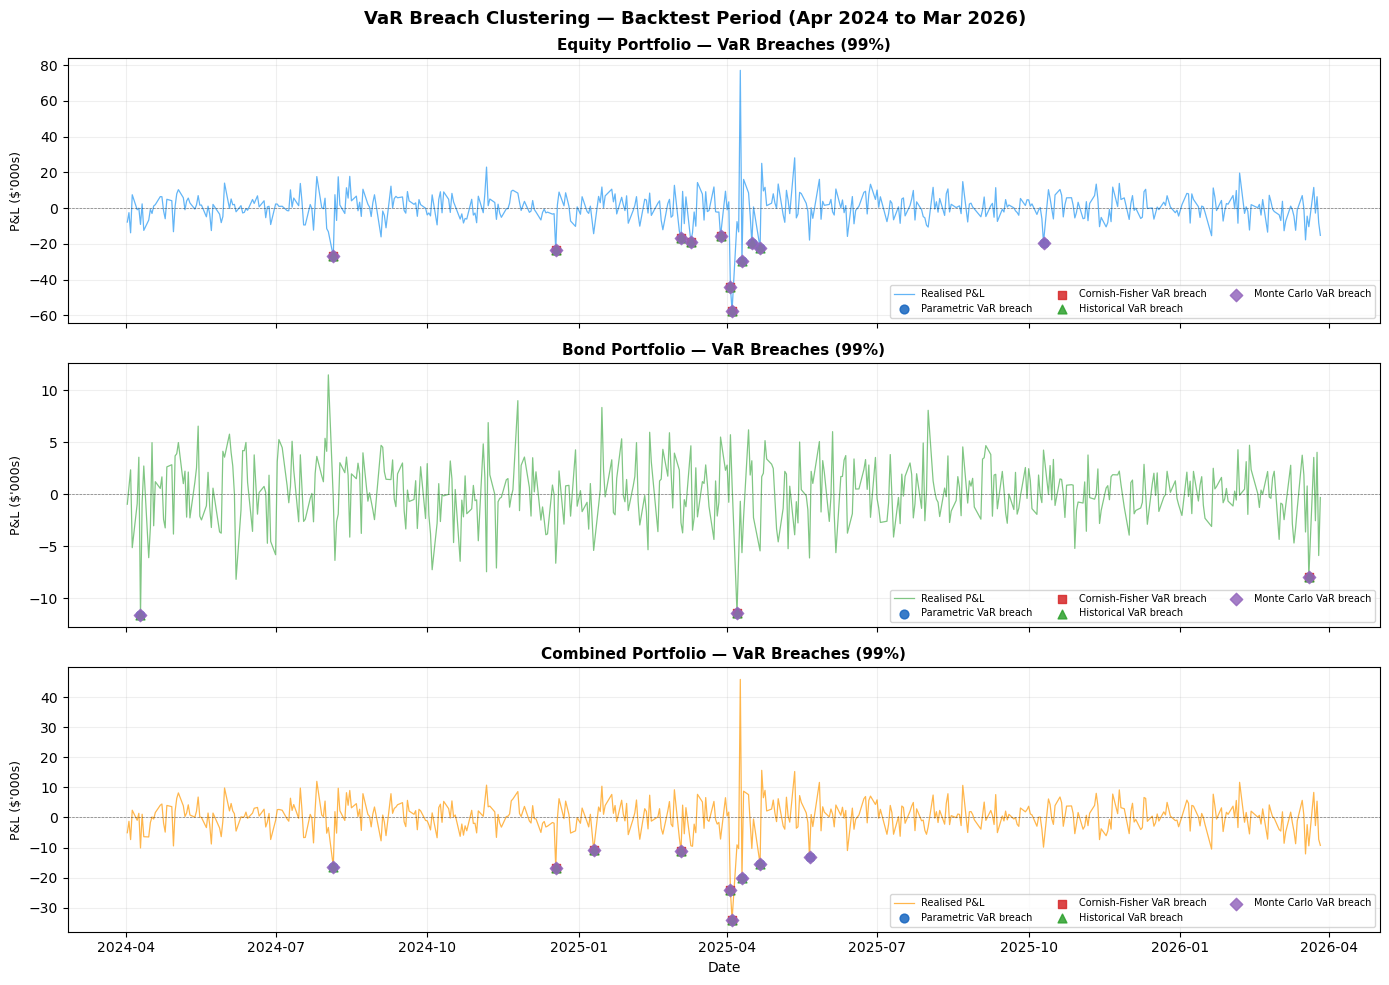

In [50]:
# -----------------------------------
# Breach clustering over time
# -----------------------------------

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for ax, (portfolio_name, color) in zip(axes, [
    ('Equity',   '#2196F3'),
    ('Bond',     '#4CAF50'),
    ('Combined', '#FF9800')
]):
    realised_pnl = rolling_results[portfolio_name][0.99]['Realised PnL']
    breach_df    = rolling_results[portfolio_name][0.99]['VaR Breaches']

    # Plot realised P&L
    ax.plot(realised_pnl.index, realised_pnl / 1000,
            color=color, linewidth=0.9, alpha=0.7, label='Realised P&L')

    # Overlay breach markers for each method
    method_markers = {
        'Parametric VaR':     ('o', '#1565C0'),
        'Cornish-Fisher VaR': ('s', '#d62728'),
        'Historical VaR':     ('^', '#2ca02c'),
        'Monte Carlo VaR':    ('D', '#9467bd'),
    }

    for method, (marker, mc) in method_markers.items():
        breach_dates = breach_df.index[breach_df[method] == 1]
        breach_vals  = realised_pnl.loc[breach_dates] / 1000
        ax.scatter(breach_dates, breach_vals, color=mc, s=40,
                   marker=marker, zorder=5, label=f'{method} breach',
                   alpha=0.85)

    ax.axhline(0, color='black', linewidth=0.5, linestyle='--', alpha=0.5)
    ax.set_title(f'{portfolio_name} Portfolio — VaR Breaches (99%)',
                 fontsize=11, fontweight='bold')
    ax.set_ylabel("P&L ($'000s)", fontsize=9)
    ax.legend(fontsize=7, ncol=3, loc='lower right')
    ax.grid(True, alpha=0.2)

axes[-1].set_xlabel('Date', fontsize=10)
plt.suptitle('VaR Breach Clustering — Backtest Period (Apr 2024 to Mar 2026)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('breach_clustering.png', dpi=150, bbox_inches='tight')
plt.show()

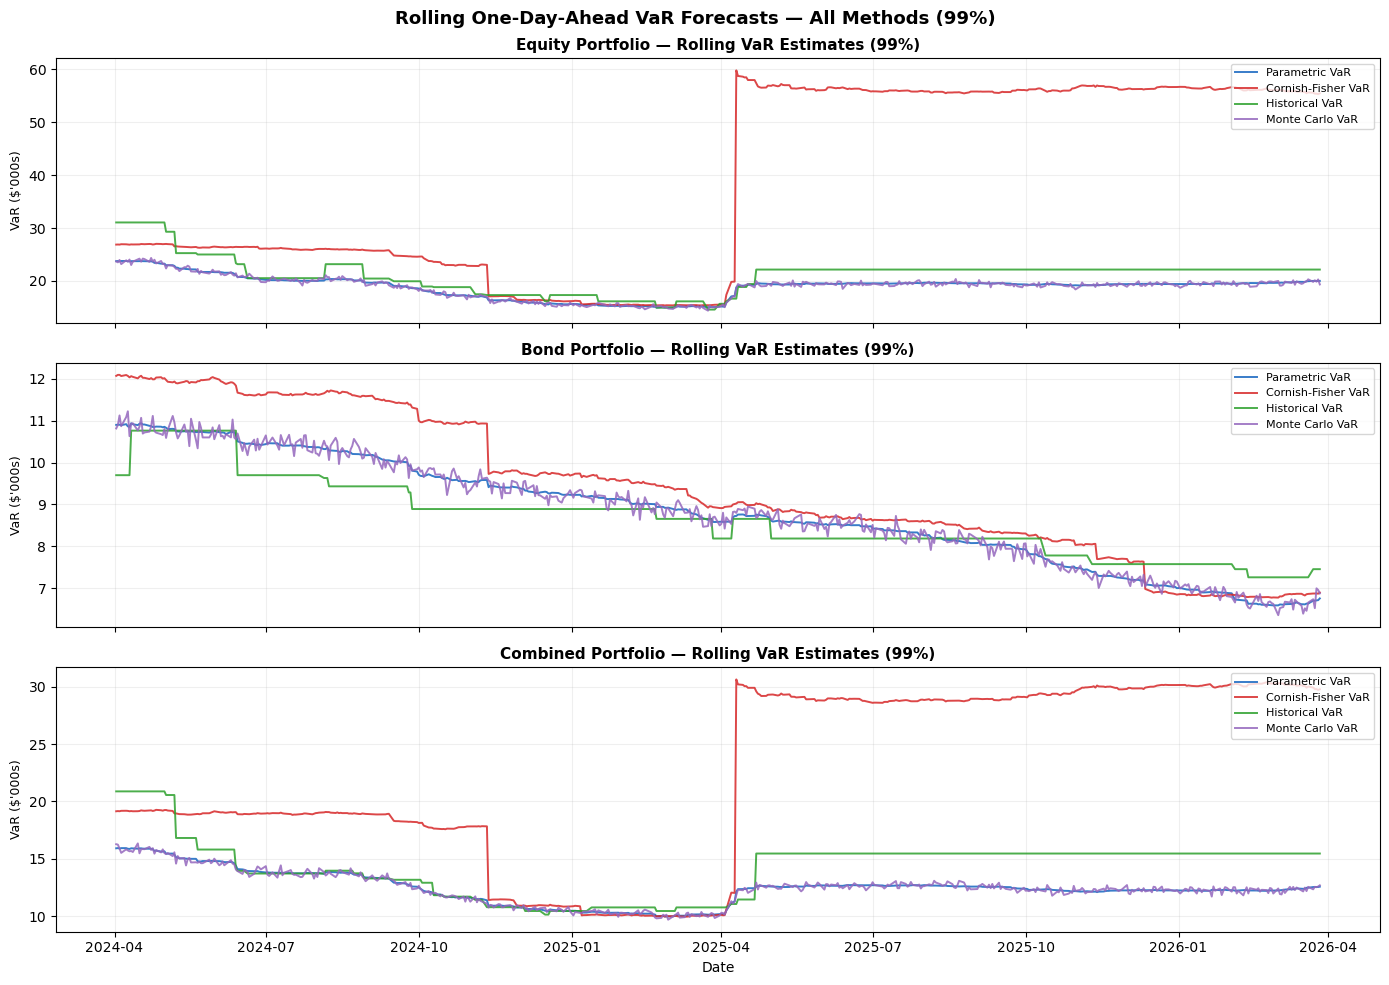

In [51]:
# -----------------------------------
# Rolling VaR forecasts over time
# -----------------------------------

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

method_colors_line = {
    'Parametric VaR':     '#1565C0',
    'Cornish-Fisher VaR': '#d62728',
    'Historical VaR':     '#2ca02c',
    'Monte Carlo VaR':    '#9467bd',
}

for ax, portfolio_name in zip(axes, ['Equity', 'Bond', 'Combined']):
    var_df = rolling_results[portfolio_name][0.99]['VaR']

    for method, mc in method_colors_line.items():
        ax.plot(var_df.index, var_df[method] / 1000,
                color=mc, linewidth=1.4, label=method, alpha=0.85)

    ax.set_title(f'{portfolio_name} Portfolio — Rolling VaR Estimates (99%)',
                 fontsize=11, fontweight='bold')
    ax.set_ylabel("VaR ($'000s)", fontsize=9)
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, alpha=0.2)

axes[-1].set_xlabel('Date', fontsize=10)
plt.suptitle('Rolling One-Day-Ahead VaR Forecasts — All Methods (99%)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('rolling_var_forecasts.png', dpi=150, bbox_inches='tight')
plt.show()

## Intro

In [52]:
# ============================================================
# PART 2 — EXPECTED SHORTFALL (ES) BACKTESTING
# ============================================================

## ES evaluation function

In [53]:
# -----------------------------------
# ES backtesting metrics
# -----------------------------------

def evaluate_es_performance(realised_pnl, var_series, es_series):
    """
    Evaluate ES forecasts based on exceedance losses.
    
    Returns:
    - number of exceedances
    - average realised loss (conditional on exceedance)
    - average ES forecast
    - ES bias
    - ES loss function (mean squared error)
    """

    realised_pnl = realised_pnl.copy()
    var_series   = var_series.copy()
    es_series    = es_series.copy()

    # Identify VaR exceedances
    exceedances = realised_pnl < -var_series

    if exceedances.sum() == 0:
        return {
            'Exceedances': 0,
            'Avg Realised Loss': np.nan,
            'Avg ES Forecast': np.nan,
            'ES Bias': np.nan,
            'ES MSE': np.nan
        }

    # Realised losses beyond VaR
    realised_losses = -realised_pnl[exceedances]
    es_forecasts    = es_series[exceedances]

    avg_realised_loss = realised_losses.mean()
    avg_es_forecast   = es_forecasts.mean()

    # Bias: forecast vs actual
    bias = avg_es_forecast - avg_realised_loss

    # Mean squared error
    mse = np.mean((es_forecasts - realised_losses) ** 2)

    return {
        'Exceedances': int(exceedances.sum()),
        'Avg Realised Loss': avg_realised_loss,
        'Avg ES Forecast': avg_es_forecast,
        'ES Bias': bias,
        'ES MSE': mse
    }

## Run ES backtests

In [54]:
# -----------------------------------
# Run ES evaluation across portfolios
# -----------------------------------

es_backtest_results = {}

for portfolio_name in rolling_results:
    es_backtest_results[portfolio_name] = {}

    for conf in confidence_levels:
        realised_pnl = rolling_results[portfolio_name][conf]['Realised PnL']
        var_df       = rolling_results[portfolio_name][conf]['VaR']
        es_df        = rolling_results[portfolio_name][conf]['ES']

        results_list = []

        for method in var_df.columns:
            res = evaluate_es_performance(
                realised_pnl=realised_pnl,
                var_series=var_df[method],
                es_series=es_df[method.replace("VaR", "ES")]
            )

            results_list.append({
                'Method': method,
                'Confidence': conf,
                **res
            })

        es_backtest_results[portfolio_name][conf] = pd.DataFrame(results_list)

## Display ES results

In [55]:
# -----------------------------------
# Display ES results
# -----------------------------------

for conf in confidence_levels:
    print("\n" + "=" * 100)
    print(f"ES BACKTEST RESULTS | CONFIDENCE LEVEL = {int(conf * 100)}%")
    print("=" * 100)

    for portfolio_name in es_backtest_results:
        print(f"\n{portfolio_name.upper()} PORTFOLIO")
        display(es_backtest_results[portfolio_name][conf])


ES BACKTEST RESULTS | CONFIDENCE LEVEL = 99%

EQUITY PORTFOLIO


,Method,Confidence,Exceedances,Avg Realised Loss,Avg ES Forecast,ES Bias,ES MSE
0,Parametric VaR,0.99,11,26694.456505,19676.109893,-7018.346612,2.170666e+08
1,Cornish-Fisher VaR,0.99,7,29022.721433,24567.498882,-4455.222551,1.798193e+08
2,Historical VaR,0.99,10,27433.220770,26401.182197,-1032.038573,2.122634e+08
3,Monte Carlo VaR,0.99,11,26694.456505,19679.590397,-7014.866108,2.158288e+08



BOND PORTFOLIO


,Method,Confidence,Exceedances,Avg Realised Loss,Avg ES Forecast,ES Bias,ES MSE
0,Parametric VaR,0.99,3,10327.135069,9972.401600,-354.733469,1.020858e+06
1,Cornish-Fisher VaR,0.99,2,9672.644188,9895.252270,222.608081,2.095790e+06
2,Historical VaR,0.99,3,10327.135069,10486.433707,159.298638,1.694794e+06
3,Monte Carlo VaR,0.99,3,10327.135069,9985.049092,-342.085976,1.028003e+06



COMBINED PORTFOLIO


...

,Method,Confidence,Exceedances,Avg Realised Loss,Avg ES Forecast,ES Bias,ES MSE
0,Parametric VaR,0.95,22,20834.007561,15390.233820,-5443.773741,1.496607e+08
1,Cornish-Fisher VaR,0.95,29,18518.415986,26310.536327,7792.120341,2.972453e+08
2,Historical VaR,0.95,26,19614.562543,17230.909779,-2383.652764,1.244004e+08
3,Monte Carlo VaR,0.95,22,20834.007561,15436.374404,-5397.633158,1.500140e+08



BOND PORTFOLIO


,Method,Confidence,Exceedances,Avg Realised Loss,Avg ES Forecast,ES Bias,ES MSE
0,Parametric VaR,0.95,12,7460.834319,7668.084283,207.249964,3.030258e+06
1,Cornish-Fisher VaR,0.95,12,7269.672094,7676.798857,407.126763,3.395661e+06
2,Historical VaR,0.95,9,7950.886232,7744.979340,-205.906892,3.191650e+06
3,Monte Carlo VaR,0.95,11,7665.448861,7749.916138,84.467278,2.968778e+06



COMBINED PORTFOLIO


,Method,Confidence,Exceedances,Avg Realised Loss,Avg ES Forecast,ES Bias,ES MSE
0,Parametric VaR,0.95,24,12695.408217,10181.432027,-2513.976189,4.448351e+07
1,Cornish-Fisher VaR,0.95,26,12262.723200,15742.707641,3479.984441,8.181739e+07
2,Historical VaR,0.95,25,12482.266404,11229.547252,-1252.719152,4.226448e+07
3,Monte Carlo VaR,0.95,24,12695.408217,10212.316430,-2483.091786,4.447026e+07


## Clean summary table

In [56]:
# -----------------------------------
# Compact ES summary table
# -----------------------------------

def create_es_summary(confidence=0.99):
    rows = []

    for portfolio_name in es_backtest_results:
        df = es_backtest_results[portfolio_name][confidence]

        for _, row in df.iterrows():
            rows.append({
                'Portfolio': portfolio_name,
                'Method': row['Method'],
                'Exceedances': row['Exceedances'],
                'Avg Realised Loss': round(row['Avg Realised Loss'], 2),
                'Avg ES Forecast': round(row['Avg ES Forecast'], 2),
                'Bias (Forecast - Actual)': round(row['ES Bias'], 2),
                'ES MSE': round(row['ES MSE'], 2)
            })

    return pd.DataFrame(rows)

es_summary_99 = create_es_summary(0.99)
es_summary_95 = create_es_summary(0.95)

print("=" * 100)
print("ES SUMMARY — 99%")
print("=" * 100)
display(es_summary_99)

print("=" * 100)
print("ES SUMMARY — 95%")
print("=" * 100)
display(es_summary_95)

ES SUMMARY — 99%


,Portfolio,Method,Exceedances,Avg Realised Loss,Avg ES Forecast,Bias (Forecast - Actual),ES MSE
0,Equity,Parametric VaR,11,26694.46,19676.11,-7018.35,2.170666e+08
1,Equity,Cornish-Fisher VaR,7,29022.72,24567.50,-4455.22,1.798193e+08
2,Equity,Historical VaR,10,27433.22,26401.18,-1032.04,2.122634e+08
3,Equity,Monte Carlo VaR,11,26694.46,19679.59,-7014.87,2.158288e+08
4,Bond,Parametric VaR,3,10327.14,9972.40,-354.73,1.020858e+06
5,Bond,Cornish-Fisher VaR,2,9672.64,9895.25,222.61,2.095790e+06
6,Bond,Historical VaR,3,10327.14,10486.43,159.30,1.694794e+06
7,Bond,Monte Carlo VaR,3,10327.14,9985.05,-342.09,1.028003e+06
8,Combined,Parametric VaR,9,17991.73,13072.70,-4919.03,7.827476e+07
9,Combined,Cornish-Fisher VaR,5,19379.99,14349.74,-5030.25,8.406457e+07


ES SUMMARY — 95%


,Portfolio,Method,Exceedances,Avg Realised Loss,Avg ES Forecast,Bias (Forecast - Actual),ES MSE
0,Equity,Parametric VaR,22,20834.01,15390.23,-5443.77,1.496607e+08
1,Equity,Cornish-Fisher VaR,29,18518.42,26310.54,7792.12,2.972453e+08
2,Equity,Historical VaR,26,19614.56,17230.91,-2383.65,1.244004e+08
3,Equity,Monte Carlo VaR,22,20834.01,15436.37,-5397.63,1.500140e+08
4,Bond,Parametric VaR,12,7460.83,7668.08,207.25,3.030258e+06
5,Bond,Cornish-Fisher VaR,12,7269.67,7676.80,407.13,3.395661e+06
6,Bond,Historical VaR,9,7950.89,7744.98,-205.91,3.191650e+06
7,Bond,Monte Carlo VaR,11,7665.45,7749.92,84.47,2.968778e+06
8,Combined,Parametric VaR,24,12695.41,10181.43,-2513.98,4.448351e+07
9,Combined,Cornish-Fisher VaR,26,12262.72,15742.71,3479.98,8.181739e+07


## Visual comparison

In [57]:
# -----------------------------------
# Visual comparison: ES vs realised losses
# -----------------------------------

def plot_es_vs_realised(portfolio_name, confidence=0.99):
    results      = rolling_results[portfolio_name][confidence]
    realised_pnl = results['Realised PnL']
    var_df       = results['VaR']
    es_df        = results['ES']

    fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True)
    axes = axes.flatten()

    for ax, method in zip(axes, var_df.columns):
        exceedances = realised_pnl < -var_df[method]

        realised_losses = -realised_pnl[exceedances]
        es_forecasts    = es_df[method.replace("VaR", "ES")][exceedances]

        ax.scatter(realised_losses, es_forecasts, alpha=0.7)
        
        max_val = max(realised_losses.max(), es_forecasts.max())
        ax.plot([0, max_val], [0, max_val], 'r--')

        ax.set_title(f"{method} — {portfolio_name}", fontsize=11)
        ax.set_xlabel("Realised Loss")
        ax.set_ylabel("ES Forecast")
        ax.grid(True, alpha=0.3)

    fig.suptitle(f"ES Forecast vs Realised Tail Losses\n"
                 f"{portfolio_name} ({int(confidence*100)}%)",
                 fontsize=14, fontweight='bold')

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

## Run ES plots

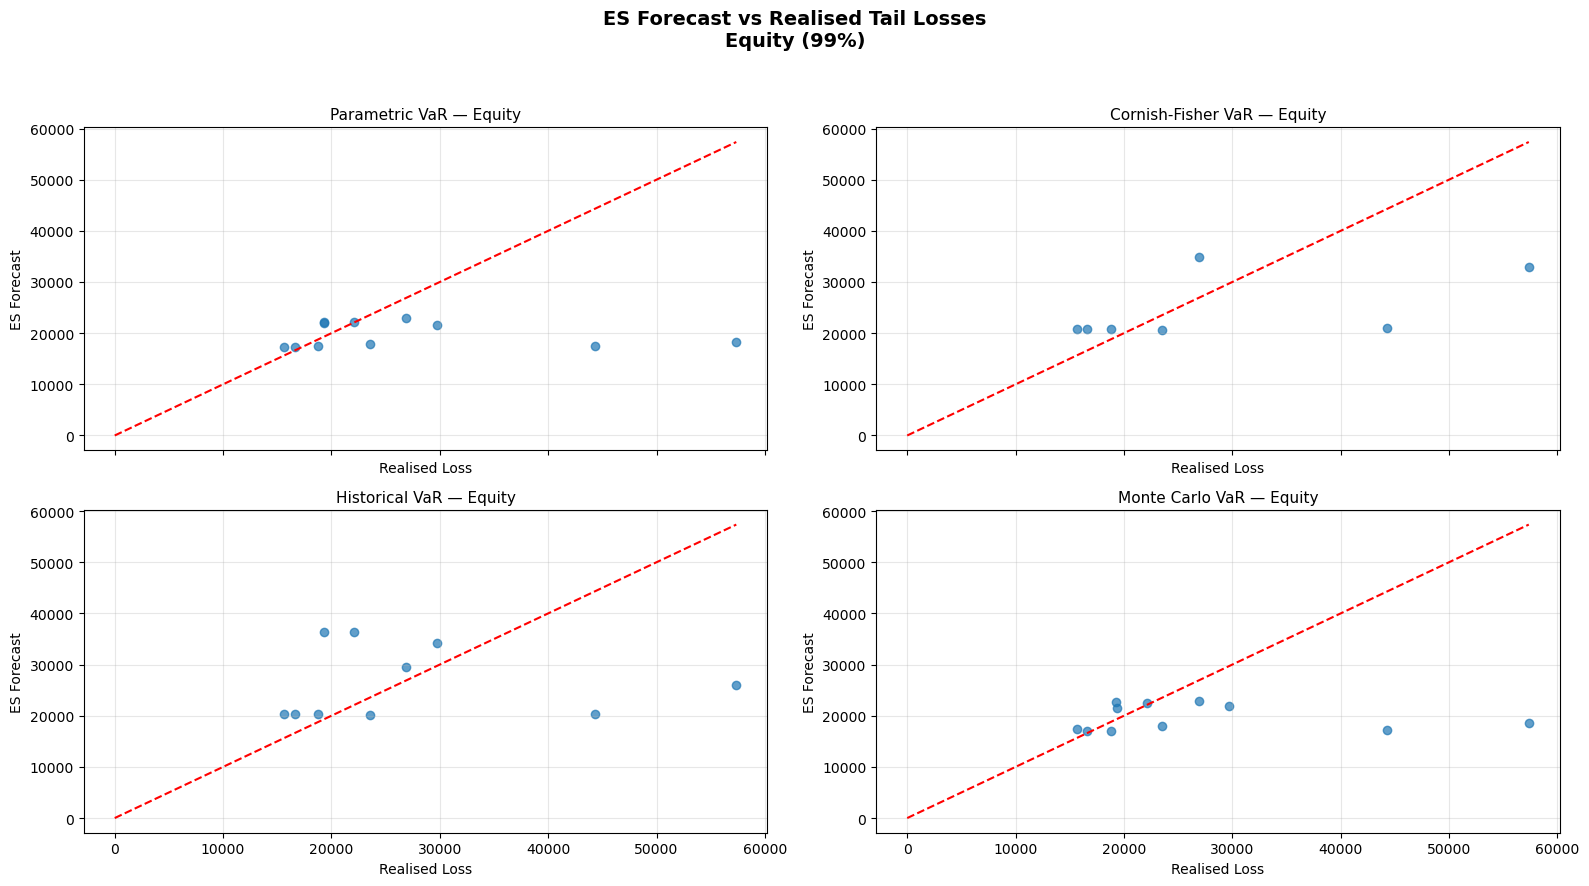

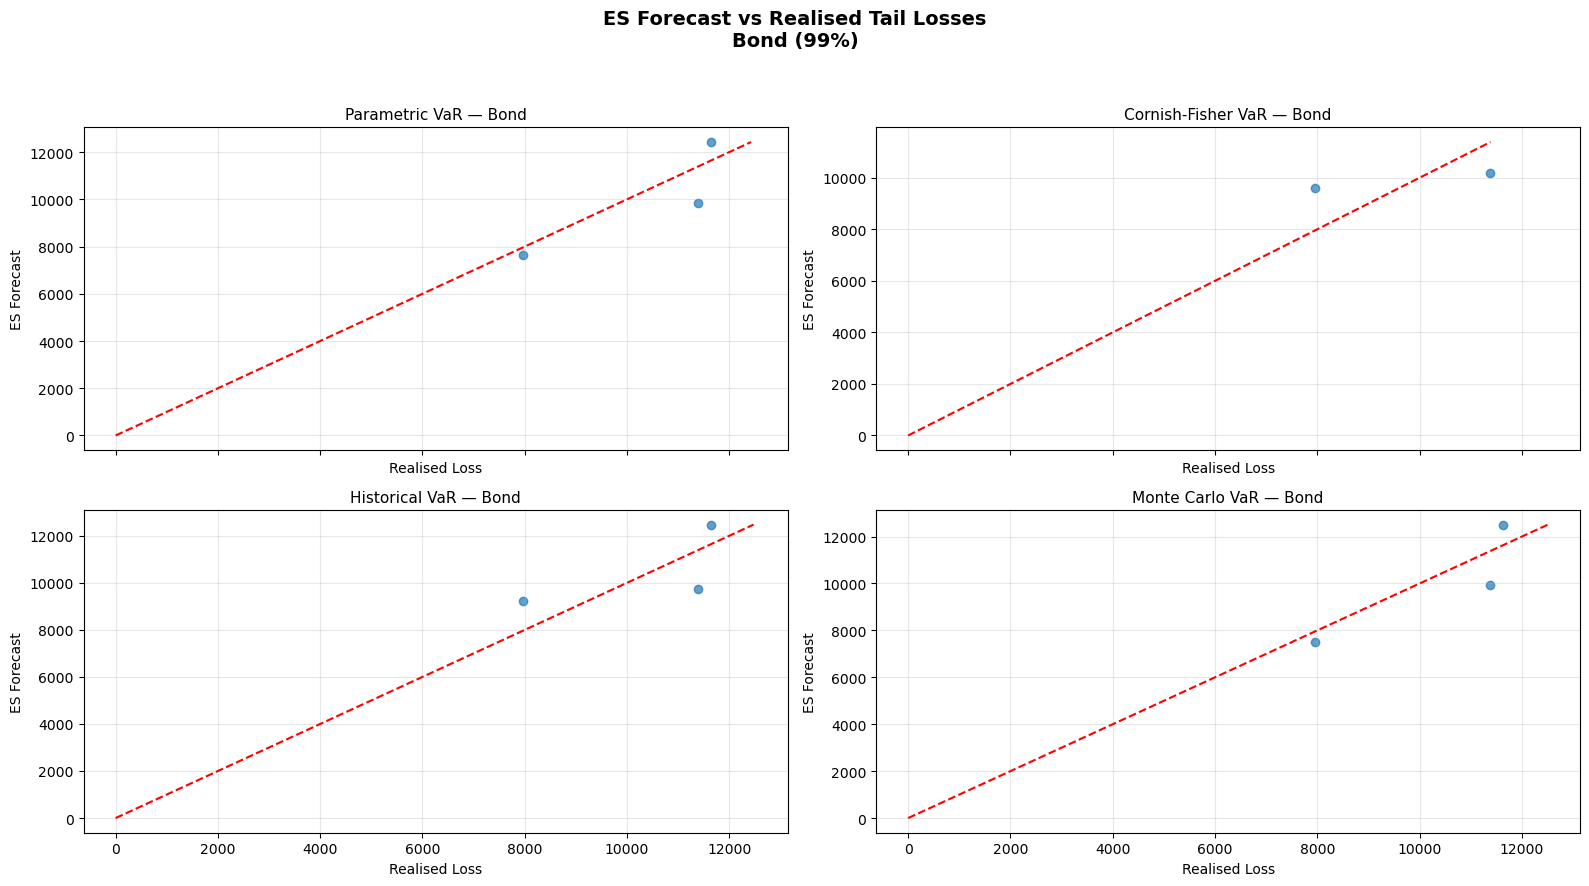

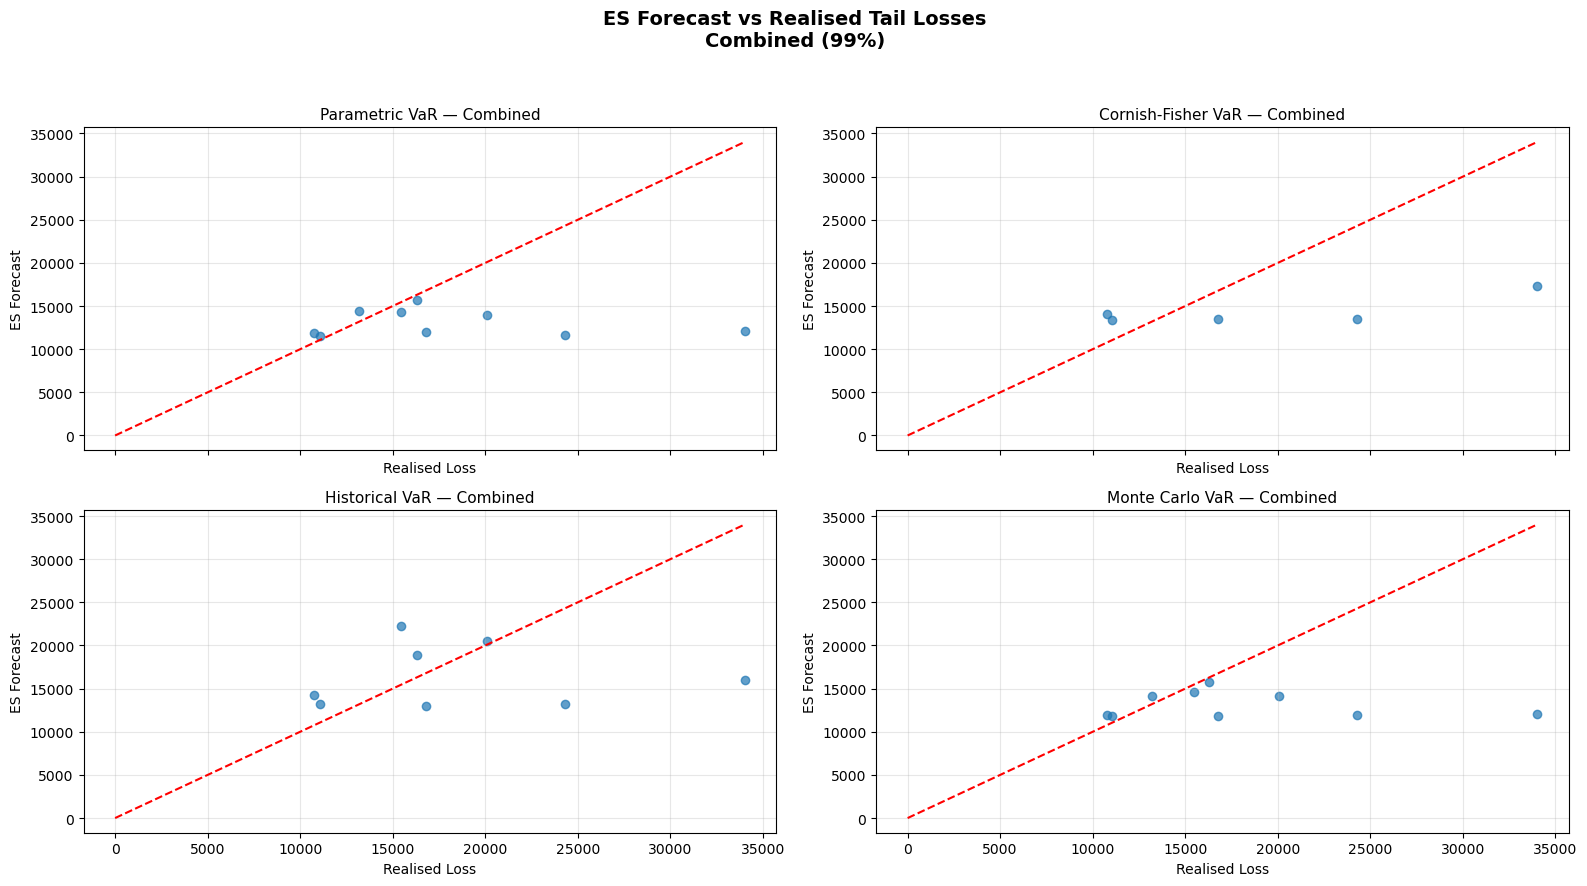

In [58]:
plot_es_vs_realised('Equity', 0.99)
plot_es_vs_realised('Bond', 0.99)
plot_es_vs_realised('Combined', 0.99)

## Ranking ES methods

In [59]:
# -----------------------------------
# Rank ES methods (lower MSE = better)
# -----------------------------------

def rank_es_methods(confidence=0.99):
    rows = []

    for portfolio_name in es_backtest_results:
        df = es_backtest_results[portfolio_name][confidence]

        for _, row in df.iterrows():
            rows.append({
                'Portfolio': portfolio_name,
                'Method': row['Method'],
                'ES MSE': row['ES MSE'],
                'Bias': row['ES Bias'],
                'Exceedances': row['Exceedances']
            })

    rank_df = pd.DataFrame(rows)
    rank_df = rank_df.sort_values(['Portfolio', 'ES MSE'])

    return rank_df

rank_es_99 = rank_es_methods(0.99)
rank_es_95 = rank_es_methods(0.95)

print("=" * 100)
print("ES METHOD RANKING — 99% (Lower MSE = Better)")
print("=" * 100)
display(rank_es_99)

print("=" * 100)
print("ES METHOD RANKING — 95% (Lower MSE = Better)")
print("=" * 100)
display(rank_es_95)

ES METHOD RANKING — 99% (Lower MSE = Better)


,Portfolio,Method,ES MSE,Bias,Exceedances
4,Bond,Parametric VaR,1.020858e+06,-354.733469,3
7,Bond,Monte Carlo VaR,1.028003e+06,-342.085976,3
6,Bond,Historical VaR,1.694794e+06,159.298638,3
5,Bond,Cornish-Fisher VaR,2.095790e+06,222.608081,2
10,Combined,Historical VaR,6.649908e+07,-2176.224686,8
11,Combined,Monte Carlo VaR,7.764243e+07,-4847.230499,9
8,Combined,Parametric VaR,7.827476e+07,-4919.032673,9
9,Combined,Cornish-Fisher VaR,8.406457e+07,-5030.246933,5
1,Equity,Cornish-Fisher VaR,1.798193e+08,-4455.222551,7
2,Equity,Historical VaR,2.122634e+08,-1032.038573,10


ES METHOD RANKING — 95% (Lower MSE = Better)


,Portfolio,Method,ES MSE,Bias,Exceedances
7,Bond,Monte Carlo VaR,2.968778e+06,84.467278,11
4,Bond,Parametric VaR,3.030258e+06,207.249964,12
6,Bond,Historical VaR,3.191650e+06,-205.906892,9
5,Bond,Cornish-Fisher VaR,3.395661e+06,407.126763,12
10,Combined,Historical VaR,4.226448e+07,-1252.719152,25
11,Combined,Monte Carlo VaR,4.447026e+07,-2483.091786,24
8,Combined,Parametric VaR,4.448351e+07,-2513.976189,24
9,Combined,Cornish-Fisher VaR,8.181739e+07,3479.984441,26
2,Equity,Historical VaR,1.244004e+08,-2383.652764,26
0,Equity,Parametric VaR,1.496607e+08,-5443.773741,22


## Extra summary tables and data visualisations (not required)

## Build final comparison table

In [60]:
# ============================================================
# EXTRA SUMMARY TABLE 1 — FINAL MODEL COMPARISON TABLE
# ============================================================

def build_final_model_comparison(confidence=0.99):
    rows = []

    # VaR scores
    var_scores = score_var_methods(confidence=confidence).copy()

    # ES rankings
    es_ranks = rank_es_methods(confidence=confidence).copy()

    for portfolio in ['Equity', 'Bond', 'Combined']:
        var_sub = var_scores[var_scores['Portfolio'] == portfolio].copy()
        es_sub  = es_ranks[es_ranks['Portfolio'] == portfolio].copy()

        # Best VaR method = highest score, then highest CC p-value
        var_best = var_sub.sort_values(
            ['Score (max 3)', 'CC p-value'],
            ascending=[False, False]
        ).iloc[0]

        # Best ES method = lowest MSE
        es_best = es_sub.sort_values('ES MSE', ascending=True).iloc[0]

        # Convert ES method labels back to common naming style if needed
        best_var_method = var_best['Method']
        best_es_method  = es_best['Method']

        # Simple final choice rule:
        # if same method wins both, choose that;
        # otherwise prefer ES winner if VaR score is still reasonably strong
        var_score_for_es_winner = var_sub.loc[var_sub['Method'] == best_es_method, 'Score (max 3)'].values[0]

        if best_var_method == best_es_method:
            final_choice = best_var_method
            rationale = "Same method performs best for both VaR and ES"
        elif var_score_for_es_winner >= 2:
            final_choice = best_es_method
            rationale = "Chosen for stronger ES performance with acceptable VaR backtesting"
        else:
            final_choice = best_var_method
            rationale = "Chosen for stronger VaR backtesting performance"

        rows.append({
            'Portfolio': portfolio,
            'Best VaR Method': best_var_method,
            'VaR Score (max 3)': int(var_best['Score (max 3)']),
            'VaR CC p-value': round(var_best['CC p-value'], 4),
            'Best ES Method': best_es_method,
            'Best ES MSE': round(es_best['ES MSE'], 2),
            'Final Recommended Method': final_choice,
            'Rationale': rationale
        })

    return pd.DataFrame(rows)

final_model_table_99 = build_final_model_comparison(confidence=0.99)

print("=" * 110)
print("FINAL MODEL COMPARISON TABLE — 99%")
print("=" * 110)
display(final_model_table_99)

FINAL MODEL COMPARISON TABLE — 99%


,Portfolio,Best VaR Method,VaR Score (max 3),VaR CC p-value,Best ES Method,Best ES MSE,Final Recommended Method,Rationale
0,Equity,Cornish-Fisher VaR,3,0.1489,Cornish-Fisher VaR,1.798193e+08,Cornish-Fisher VaR,Same method performs best for both VaR and ES
1,Bond,Parametric VaR,3,0.6153,Parametric VaR,1.020858e+06,Parametric VaR,Same method performs best for both VaR and ES
2,Combined,Historical VaR,3,0.1279,Historical VaR,6.649908e+07,Historical VaR,Same method performs best for both VaR and ES


## Integrated summary table

In [61]:
# ============================================================
# EXTRA SUMMARY TABLE 2 — INTEGRATED PERFORMANCE TABLE
# ============================================================

def build_integrated_performance_table(confidence=0.99):
    rows = []

    for portfolio in ['Equity', 'Bond', 'Combined']:
        var_df = var_backtest_results[portfolio][confidence].copy()
        es_df  = es_backtest_results[portfolio][confidence].copy()

        merged = var_df.merge(
            es_df[['Method', 'Exceedances', 'Avg Realised Loss', 'Avg ES Forecast', 'ES Bias', 'ES MSE']],
            on='Method',
            how='left'
        )

        for _, row in merged.iterrows():
            rows.append({
                'Portfolio': portfolio,
                'Method': row['Method'],
                'Breaches': int(row['Breaches']),
                'Kupiec p': round(row['Kupiec p-value'], 4),
                'Independence p': round(row['Independence p-value'], 4),
                'CC p': round(row['Conditional Coverage p-value'], 4),
                'ES Exceedances': int(row['Exceedances']),
                'Avg Tail Loss': round(row['Avg Realised Loss'], 2),
                'Avg ES Forecast': round(row['Avg ES Forecast'], 2),
                'ES Bias': round(row['ES Bias'], 2),
                'ES MSE': round(row['ES MSE'], 2)
            })

    return pd.DataFrame(rows)

integrated_table_99 = build_integrated_performance_table(confidence=0.99)

print("=" * 120)
print("INTEGRATED VaR + ES PERFORMANCE TABLE — 99%")
print("=" * 120)
display(integrated_table_99)

INTEGRATED VaR + ES PERFORMANCE TABLE — 99%


,Portfolio,Method,Breaches,Kupiec p,Independence p,CC p,ES Exceedances,Avg Tail Loss,Avg ES Forecast,ES Bias,ES MSE
0,Equity,Parametric VaR,11,0.0196,0.2324,0.0322,11,26694.46,19676.11,-7018.35,2.170666e+08
1,Equity,Cornish-Fisher VaR,7,0.3939,0.0791,0.1489,7,29022.72,24567.50,-4455.22,1.798193e+08
2,Equity,Historical VaR,10,0.0473,0.1861,0.0584,10,27433.22,26401.18,-1032.04,2.122634e+08
3,Equity,Monte Carlo VaR,11,0.0196,0.2324,0.0322,11,26694.46,19679.59,-7014.87,2.158288e+08
4,Bond,Parametric VaR,3,0.3336,0.8488,0.6153,3,10327.14,9972.40,-354.73,1.020858e+06
5,Bond,Cornish-Fisher VaR,2,0.1260,0.8989,0.3077,2,9672.64,9895.25,222.61,2.095790e+06
6,Bond,Historical VaR,3,0.3336,0.8488,0.6153,3,10327.14,10486.43,159.30,1.694794e+06
7,Bond,Monte Carlo VaR,3,0.3336,0.8488,0.6153,3,10327.14,9985.05,-342.09,1.028003e+06
8,Combined,Parametric VaR,9,0.1049,0.1451,0.0929,9,17991.73,13072.70,-4919.03,7.827476e+07
9,Combined,Cornish-Fisher VaR,5,0.9964,0.0344,0.1067,5,19379.99,14349.74,-5030.25,8.406457e+07


## ES MSE bar charts

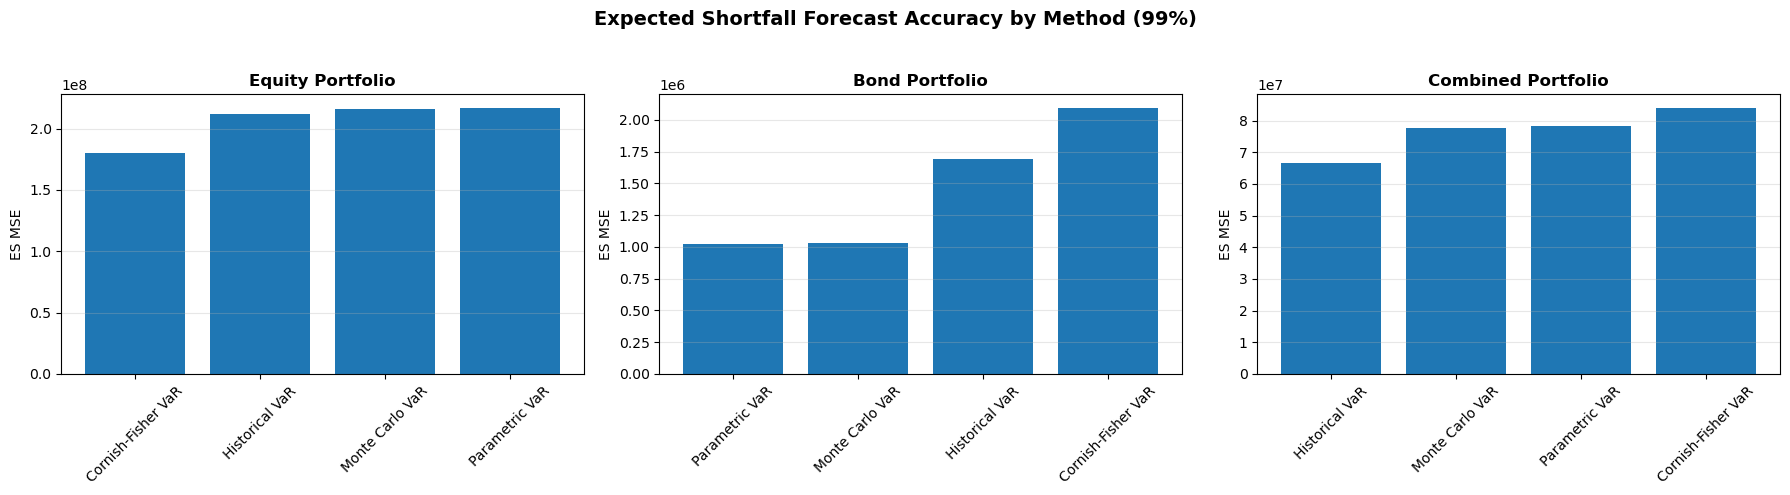

In [62]:
# ============================================================
# EXTRA VISUAL 1 — ES MSE BAR CHARTS
# ============================================================

def plot_es_mse_bars(confidence=0.99):
    portfolios_list = ['Equity', 'Bond', 'Combined']

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

    for ax, portfolio in zip(axes, portfolios_list):
        df = es_backtest_results[portfolio][confidence].copy()
        df = df.sort_values('ES MSE')

        ax.bar(df['Method'], df['ES MSE'])
        ax.set_title(f'{portfolio} Portfolio', fontsize=12, fontweight='bold')
        ax.set_ylabel('ES MSE')
        ax.tick_params(axis='x', rotation=45)
        ax.grid(True, axis='y', alpha=0.3)

    fig.suptitle(f'Expected Shortfall Forecast Accuracy by Method ({int(confidence*100)}%)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

plot_es_mse_bars(0.99)

## Conditional coverage chart

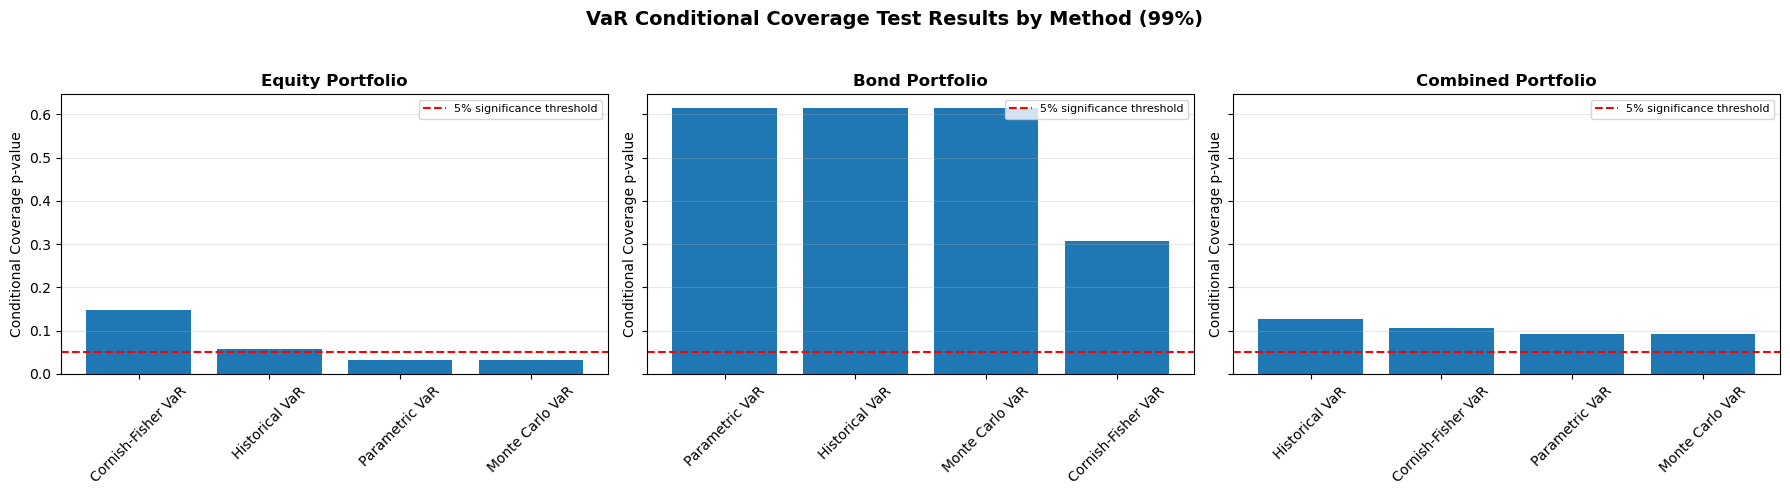

In [61]:
# ============================================================
# EXTRA VISUAL 2 — VaR CONDITIONAL COVERAGE P-VALUE CHART
# ============================================================

def plot_cc_pvalues(confidence=0.99):
    portfolios_list = ['Equity', 'Bond', 'Combined']

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

    for ax, portfolio in zip(axes, portfolios_list):
        df = var_backtest_results[portfolio][confidence].copy()
        df = df.sort_values('Conditional Coverage p-value', ascending=False)

        ax.bar(df['Method'], df['Conditional Coverage p-value'])
        ax.axhline(0.05, c='r', linestyle='--', linewidth=1.5, label='5% significance threshold')
        ax.set_title(f'{portfolio} Portfolio', fontsize=12, fontweight='bold')
        ax.set_ylabel('Conditional Coverage p-value')
        ax.tick_params(axis='x', rotation=45)
        ax.grid(True, axis='y', alpha=0.3)
        ax.legend(fontsize=8)

    fig.suptitle(f'VaR Conditional Coverage Test Results by Method ({int(confidence*100)}%)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

plot_cc_pvalues(0.99)

## Final scorecard table

In [62]:
# ============================================================
# EXTRA SUMMARY TABLE 3 — FINAL SCORECARD
# ============================================================

def build_final_scorecard(confidence=0.99):
    rows = []

    for portfolio in ['Equity', 'Bond', 'Combined']:
        var_df = var_backtest_results[portfolio][confidence].copy()
        es_df  = es_backtest_results[portfolio][confidence].copy()

        merged = var_df.merge(
            es_df[['Method', 'ES MSE', 'ES Bias']],
            on='Method',
            how='left'
        )

        # Rank ES MSE within each portfolio
        merged['ES Rank'] = merged['ES MSE'].rank(method='dense', ascending=True).astype(int)

        # Total score: VaR pass score + ES rank score
        merged['VaR Score'] = (
            (~merged['Kupiec Reject 5%']).astype(int) +
            (~merged['Independence Reject 5%']).astype(int) +
            (~merged['Conditional Coverage Reject 5%']).astype(int)
        )

        # Higher is better
        merged['Overall Score'] = merged['VaR Score'] + (5 - merged['ES Rank'])

        for _, row in merged.iterrows():
            rows.append({
                'Portfolio': portfolio,
                'Method': row['Method'],
                'VaR Score (max 3)': int(row['VaR Score']),
                'ES Rank (1=Best)': int(row['ES Rank']),
                'Overall Score': int(row['Overall Score']),
                'CC Pass?': 'Yes' if not row['Conditional Coverage Reject 5%'] else 'No',
                'ES Bias': round(row['ES Bias'], 2)
            })

    scorecard = pd.DataFrame(rows)
    scorecard = scorecard.sort_values(['Portfolio', 'Overall Score'], ascending=[True, False])

    return scorecard

final_scorecard_99 = build_final_scorecard(confidence=0.99)

print("=" * 110)
print("FINAL SCORECARD — 99%")
print("=" * 110)
display(final_scorecard_99)

FINAL SCORECARD — 99%


,Portfolio,Method,VaR Score (max 3),ES Rank (1=Best),Overall Score,CC Pass?,ES Bias
4,Bond,Parametric VaR,3,1,7,Yes,-354.73
7,Bond,Monte Carlo VaR,3,2,6,Yes,-342.09
6,Bond,Historical VaR,3,3,5,Yes,159.30
5,Bond,Cornish-Fisher VaR,3,4,4,Yes,222.61
10,Combined,Historical VaR,3,1,7,Yes,-2176.22
11,Combined,Monte Carlo VaR,3,2,6,Yes,-4847.23
8,Combined,Parametric VaR,3,3,5,Yes,-4919.03
9,Combined,Cornish-Fisher VaR,2,4,3,Yes,-5030.25
1,Equity,Cornish-Fisher VaR,3,1,7,Yes,-4455.22
2,Equity,Historical VaR,2,2,5,Yes,-1032.04
